<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/17_Vehicle_CAN_Bus_Attacks/QRBM_CANIntrusion_Salek2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum-classical CAN intrusion detection with a quantum RBM: Salek et al. (2023) step by step

This notebook re-implements, runs and checks the method of

> M Sabbir Salek, Pronab Kumar Biswas, Jacquan Pollard, Jordyn Hales, Zecheng Shen, Vivek Dixit, Mashrur Chowdhury,
> Sakib Mahmud Khan and Yao Wang, "A Novel Hybrid Quantum-Classical Framework for an In-Vehicle Controller Area Network
> Intrusion Detection", *IEEE Access*, 2023. https://doi.org/10.1109/ACCESS.2023.3304331

The paper turns the messages of one CAN ID into small images, shrinks every image to an 8 x 8 binary picture with a classical
neural network, writes the label (attack / normal) into two extra pixel columns, and trains a **restricted Boltzmann machine
(RBM)** with 64 visible and 64 hidden units to *reconstruct* the picture. To classify a test picture the label pixels are replaced
by random bits, the RBM reconstructs the picture, and the majority of the 16 reconstructed label pixels is the verdict. The
"quantum" part is how the RBM is sampled: a **D-Wave quantum annealer** draws the samples instead of the usual classical
contrastive-divergence (CD) Gibbs step. The authors report that the quantum RBM beats the classical RBM on three CAN IDs.

**What this notebook does.**
1. Downloads the real HCRL *Survival Analysis* fuzzy-attack log of a KIA Soul (the dataset the paper cites) and decodes it with the
   OpenDBC `hyundai_kia_generic.dbc` file into vehicle signals.
2. Builds the paper's three datasets (CAN IDs 0x220, 0x316, 0x329), CAN images, the classical feature-extraction network, the 8 x 6 binary images and the label-embedded 8 x 8 images.
3. Trains a **classical RBM** (CD-1, sigmoid sampling) and a **quantum-annealing RBM** whose conditional layers are sampled from a
   *simulated closed-system quantum annealer* (a transverse-field circuit, simulated exactly, drawn with PennyLane and checked
   against an independent state-vector calculation). D-Wave hardware is not needed.
4. Adds RandomForest, SVC and the feature-extraction network itself as baselines on identical inputs, a sweep over the annealing time, a leakage-free sliding-window variant, and a claim-by-claim comparison with the paper.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
PennyLane, dimod and dwave-samplers (PyTorch, scikit-learn and matplotlib are preinstalled on Colab). No GPU, no D-Wave account and no token are needed
(the data is a public Dropbox share of the Hacking and Countermeasure Research Lab).

**Runtime.** `FAST_MODE = True` (3 random splits, short budgets) is a class demo of a few minutes. `FAST_MODE = False` is the full run
(10 random splits, the larger hyper-parameter grid); the measured duration is printed at the end.

**What you get at the end.** Dataset plots, the executed annealing circuit, accuracy / recall tables of every model next to the paper's Fig. 6 values,
confusion matrices, learning curves, an annealing-time sweep and an honest verdict on every claim that can be checked.

## The paper in one page

**Problem.** The CAN bus of a car has no authentication, so an attacker can inject frames. Fuzzy attack: frames with random IDs and random payloads.

**Decision.** Binary: a CAN image is *normal* (label bits 0) or *attack* (label bits 1).

**Data (Section IV-A, Table I).** HCRL fuzzy-attack log of a KIA Soul (ref. [35], Han, Kwak and Kim 2018). Messages are split by CAN ID; three IDs are used:
dataset 1 = 0x220, dataset 2 = 0x316, dataset 3 = 0x329. Table I: 2384 / 2648 / 1800 messages, half normal and half injected, with 14 / 13 / 19 decoded features.

**Pipeline (Section III, Figs. 1 and 2).**
1. Decode the payload with the generic KIA DBC from OpenDBC -> N signals per message.
2. *Primary CAN image*: N consecutive messages of one ID -> an N x N image (row = message, column = signal).
3. *Feature extraction*: a classical NN maps each image to an 8 x 8 secondary image, resized to 8 x 6 and thresholded at 0.5 -> binary.
4. *Label embedding*: an 8 x 2 block of ones (attack) or zeros (normal) is appended -> 8 x 8 = 64 bits.
5. *RBM* with 64 visible and 64 hidden units (64 + 64 biases, 64 x 64 weights), trained on the training images (80 %).
   Classical: CD. Quantum: sampling by a D-Wave Advantage 4.1 annealer (QUBO of the RBM energy).
6. *Test*: label bits replaced by random bits, picture reconstructed by the RBM, label = majority of the 16 reconstructed label bits.

**Claims (Fig. 6, abstract).**

| Claim | Paper value |
|---|---|
| Quantum RBM accuracy, datasets 1 / 2 / 3 | 97.5 % / 97 % / 98.3 % |
| Quantum RBM recall (attack = positive), datasets 1 / 2 / 3 | 94.7 % / 93.9 % / 97.2 % |
| Classical RBM accuracy | 86.7 % / 95 % / 89.7 % |
| Classical RBM recall | 70.7 % / 89.8 % / 80.6 % |
| The hybrid framework beats the classical-only one on all three datasets (accuracy and recall) | qualitative |
| Table I: dataset sizes (2384 / 2648 / 1800), 50 % injected, features 14 / 13 / 19 | Table I |
| Both RBMs converge in a comparable number of epochs | qualitative |

### What follows the paper and what had to be chosen

The paper does not give the network sizes, the optimiser, the annealing parameters or the exact image construction; the public scripts
(`msabbirsalek/Restricted-Boltzmann-Machine-for-CAN-IDS` and the QRBM library of M. Subocz that it uses) fill part of the gap. Everything unspecified is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Raw data | HCRL fuzzy log, KIA Soul, ref. [35], per-ID message counts of Table I (1192 / 1324 / 900 injected) | The same HCRL Survival-Analysis `Fuzzy_dataset_KIA.txt`. **It holds only 20 / 23 / 23 injected frames that carry the three IDs** (the fuzzer draws IDs uniformly from 0x000 to 0x7FF), so the paper's class sizes cannot be built by filtering on the ID. `# CHOICE`: the attack class of dataset *k* is made of Table I's number of **real injected frames of any ID (time order, disjoint blocks), decoded with the layout of the target ID**; the fuzzing payload is random and independent of the ID (checked statistically below). Normal class: the **last** Table-I-many real normal frames of the target ID (as the public script does). |
| Decoding | "generic DBC from OpenDBC" | OpenDBC commit `ed3af3d` `hyundai_kia_generic.dbc` (messages ESP12 0x220, EMS11 0x316, EMS12 0x329); decoder written here (little-endian, multiplexed signals not selected -> 0). Gives exactly 14 / 13 / 19 features |
| Primary image | N consecutive messages of one ID -> N x N | non-overlapping windows of N messages (as in the public script), label = attack if any message is injected (windows are class-pure here) |
| Feature extractor | "a classical NN" [18] | `Flatten - Dense(100, relu) - Dense(64) - Dense(16) - Dense(1)` (the public script), Adam 1e-3, batch 8, 100 epochs; the 64-unit layer is the 8 x 8 code |
| Resize 8 x 8 -> 8 x 6, binarise | resize, threshold 0.5 | per-image min-max to [0, 1], adaptive average pooling to 8 x 6, threshold 0.5 |
| Scalers | not stated | `StandardScaler` then `MinMaxScaler`, **fitted on the training images only** |
| Split | random 80 % / 20 % | stratified 80 / 20 of the images, **repeated over several seeds** (the test sets are tiny: 19 to 41 images) |
| RBM | 64 visible, 64 hidden, CD vs QA-sampled | same sizes; weights and biases initialised U(-1, 1) as in the library; one training image per update, cyclic order, lr, number of updates as below |
| Quantum sampler | D-Wave Advantage 4.1, QUBO of the RBM energy | a **simulated transverse-field quantum annealer** (Trotterised circuit, simulated exactly, PennyLane QNode drawn and checked) on the **QUBO of each conditional layer**, which is what the library does; D-Wave's coefficient auto-scaling is imitated by a range limit `H_RANGE`. Anneal time `ANNEAL_T` is a free parameter (swept). Closed system, no hardware noise, no embedding |
| Hyper-parameters | "optimised to yield the best performance" (on what is not said) | two settings: the public script's (50 single-image updates, lr 0.1) and a small grid (updates x lr) chosen **on a validation split** of the training images |
| Test procedure | random label bits, one reconstruction, majority of 16 label bits | the same |
| Baselines | classical RBM only | classical RBM, ground-state sampler, RandomForest, SVC (rbf), the extractor network itself, all on the identical 8 x 6 binary images (and on the 64-value code) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line only runs on Colab or where one of the packages is missing; a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
def _have(name):
    try:
        return importlib.util.find_spec(name) is not None
    except Exception:
        return False
if IN_COLAB or not (_have("pennylane") and _have("dimod") and _have("dwave.samplers")):
    %pip install -q "pennylane==0.45.1" "dimod==0.12.22" "dwave-samplers==1.8.0"
print("setup done (if Colab asks you to restart the session, do so and run all cells again)")

setup done (if Colab asks you to restart the session, do so and run all cells again)


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo in a few minutes. False: 10 random splits and the full hyper-parameter grid.
SEED      = 42              # CHOICE: the paper gives no seed
IBM_TOKEN = ""              # unused here (kept for template compatibility); no quantum hardware is needed

N_SEEDS     = 3 if FAST_MODE else 10      # random 80/20 splits per dataset (paper: one split)
N_SEEDS_B   = 2 if FAST_MODE else 3       # seeds of the sliding-window variant
TEST_SIZE   = 0.2                         # paper: 80 % / 20 %
VAL_FRAC    = 0.25                        # share of the training images used to choose RBM hyper-parameters

NN_EPOCHS   = 30 if FAST_MODE else 100    # feature-extraction network (public script: 100 epochs, batch 8)
NN_BATCH    = 8
NN_LR       = 1e-3

N_VISIBLE, N_HIDDEN = 64, 64              # paper: 64 + 64
SCRIPT_UPDATES, SCRIPT_LR = 50, 0.1       # public script: 50 "epochs" (= single-image updates), lr 0.1
GRID_UPDATES = [50, 300, 1000] if FAST_MODE else [50, 300, 1500]
GRID_LR      = [0.02, 0.1]

ANNEAL_T      = 10.0      # CHOICE: anneal time in units of 1/Gamma (transverse field Gamma = 1); the paper does not give it
TROTTER_MIN   = 20        # Trotter steps K = max(TROTTER_MIN, round(2.5 * T))
H_RANGE       = 4.0       # CHOICE: largest |linear coefficient| the "hardware" accepts (D-Wave h range is [-4, 4]); larger problems are scaled down
T_SWEEP       = [2.0, 5.0, 10.0, 20.0, 50.0]
SWEEP_UPDATES, SWEEP_LR = 300, 0.05

DATA_DIR   = "can_data"      # cache (relative to the working directory)
LOCAL_FILE = ""              # optional: path of an already downloaded Fuzzy_dataset_KIA.txt
# Public Dropbox share of the HCRL "Survival Analysis Dataset for automobile IDS" (page: https://ocslab.hksecurity.net/Datasets/survival-ids)
SURVIVAL_URL = ("https://www.dropbox.com/scl/fo/mqsp1orzaqjwu61j69amr/ANiI9XBqJHH5kLDUbrjrFw4"
                "?rlkey=87nphryu8yz0zz9atd436wx36&dl=1")
SURVIVAL_ZIP_PASSWORD = "ai.spera!+"   # the zip password the dataset owners print next to the download link on their page (not a secret)
DBC_URL = ("https://raw.githubusercontent.com/commaai/opendbc/ed3af3da1b7d52aed910f22cc5540e31f92ba254/hyundai_kia_generic.dbc")

# Paper: Table I (class sizes, features) and Fig. 6 / abstract (accuracy, recall in %)
TARGETS = [("dataset 1", 0x220, "ESP12", 544), ("dataset 2", 0x316, "EMS11", 790), ("dataset 3", 0x329, "EMS12", 809)]
PAPER_T1 = {"dataset 1": dict(size=2384, att=1192, feat=14), "dataset 2": dict(size=2648, att=1324, feat=13),
            "dataset 3": dict(size=1800, att=900, feat=19)}
PAPER = {  # (accuracy, recall) in %
    ("dataset 1", "QRBM"): (97.5, 94.7), ("dataset 2", "QRBM"): (97.0, 93.9), ("dataset 3", "QRBM"): (98.3, 97.2),
    ("dataset 1", "CRBM"): (86.7, 70.7), ("dataset 2", "CRBM"): (95.0, 89.8), ("dataset 3", "CRBM"): (89.7, 80.6)}

In [3]:
import os, io, re, time, zipfile, shutil, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import torch, torch.nn as nn, torch.nn.functional as F
import sklearn, scipy, dimod, dwave.samplers
import pennylane as qml
from scipy import stats
from dwave.samplers import SimulatedAnnealingSampler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.svm import SVC

torch.set_num_threads(1)
np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
T_NOTEBOOK_START = time.time()
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__)
print("pennylane", qml.__version__, "| dimod", dimod.__version__, "| dwave-samplers", dwave.samplers.__version__)
print("FAST_MODE =", FAST_MODE, "| N_SEEDS =", N_SEEDS, "| NN_EPOCHS =", NN_EPOCHS, "| grid =", GRID_UPDATES, GRID_LR)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu
pennylane 0.45.1 | dimod 0.12.22 | dwave-samplers 1.8.0
FAST_MODE = False | N_SEEDS = 10 | NN_EPOCHS = 100 | grid = [50, 300, 1500] [0.02, 0.1]


## 1. The HCRL fuzzy-attack log of a KIA Soul

The paper's reference [35] is the HCRL *Survival Analysis* dataset (Han, Kwak and Kim, 2018). It contains, for three cars, a
Flooding, a Fuzzy and a Malfunction attack log plus attack-free driving. The KIA Soul fuzzy log `Fuzzy_dataset_KIA.txt` has one CAN frame per line:

`timestamp, CAN ID (hex), DLC, DATA[0] ... DATA[DLC-1] (hex), flag`

with `flag = R` for a regular frame and `T` for an injected one. The fuzzer injects a frame every 0.3 ms with a random ID (0x000 to 0x7FF) and a random payload, for about 10 seconds in each of four windows.
The dataset is a public Dropbox share (13.7 MB zip containing a zip); the owners print the zip password on their download page, and it is set in the configuration cell.
Only the one needed file (12.9 MB) is kept in `DATA_DIR`.

In [4]:
def download(url, dest):
    with requests.get(url, stream=True, timeout=180) as r:
        r.raise_for_status()
        with open(dest, "wb") as fh:
            for ch in r.iter_content(1 << 20):
                fh.write(ch)

def ensure_fuzzy_file():
    final = os.path.join(DATA_DIR, "Fuzzy_dataset_KIA.txt")
    if LOCAL_FILE and os.path.exists(LOCAL_FILE):
        return LOCAL_FILE
    if os.path.exists(final) and os.path.getsize(final) > 1e6:
        return final
    outer, inner = os.path.join(DATA_DIR, "hcrl_outer.zip"), os.path.join(DATA_DIR, "hcrl_survival.zip")
    print("downloading the HCRL survival-analysis share (13.7 MB) ...", flush=True)
    download(SURVIVAL_URL, outer)
    with zipfile.ZipFile(outer) as z:
        member = next(i for i in z.infolist() if i.filename.lower().endswith("survival.zip"))
        with z.open(member) as src, open(inner, "wb") as dst:
            shutil.copyfileobj(src, dst)
    with zipfile.ZipFile(inner) as z2:
        name = next(n for n in z2.namelist() if n.endswith("Soul/Fuzzy_dataset_KIA.txt"))
        with z2.open(name, pwd=SURVIVAL_ZIP_PASSWORD.encode()) as src, open(final, "wb") as dst:   # fixed output path only
            shutil.copyfileobj(src, dst)
    os.remove(outer); os.remove(inner)
    return final

def parse_frames(path):
    """One pass over the log: timestamp, CAN ID, DLC, payload (8 bytes, zero padded), injected flag."""
    ts, cid, dlc, pay, att = [], [], [], [], []
    with open(path) as f:
        for line in f:
            p = line.strip().split(",")
            d = int(p[2])
            if len(p) != 4 + d:
                continue
            b = [int(x, 16) for x in p[3:3 + d]] + [0] * (8 - d)
            ts.append(float(p[0])); cid.append(int(p[1], 16)); dlc.append(d); pay.append(b); att.append(p[3 + d] == "T")
    return (np.array(ts), np.array(cid, dtype=np.int32), np.array(dlc, dtype=np.int8),
            np.array(pay, dtype=np.uint8), np.array(att, dtype=bool))

t0 = time.time()
RAW_PATH = ensure_fuzzy_file()
cache = os.path.join(DATA_DIR, "fuzzy_kia_parsed.npz")
if os.path.exists(cache):
    z = np.load(cache); TS, CID, DLC, PAY, ATT = z["ts"], z["cid"], z["dlc"], z["pay"], z["att"]
else:
    TS, CID, DLC, PAY, ATT = parse_frames(RAW_PATH)
    np.savez_compressed(cache, ts=TS, cid=CID, dlc=DLC, pay=PAY, att=ATT)
print(f"raw log: {os.path.basename(RAW_PATH)}, {os.path.getsize(RAW_PATH)/1e6:.1f} MB, parsed in {time.time()-t0:.0f} s")
with open(RAW_PATH) as f:
    for _ in range(3): print(f.readline().rstrip())
print(f"{len(TS)} frames, {ATT.sum()} injected (T), {(~ATT).sum()} regular (R), "
      f"{len(np.unique(CID[~ATT]))} distinct regular IDs, {len(np.unique(CID[ATT]))} distinct injected IDs, DLC values {sorted(set(DLC.tolist()))}")

downloading the HCRL survival-analysis share (13.7 MB) ...


raw log: Fuzzy_dataset_KIA.txt, 12.9 MB, parsed in 17 s
1513920167.161964,0081,8,40,84,4E,00,00,00,00,A4,R
1513920167.162236,02A0,8,02,00,4E,9C,F0,0F,33,03,R
1513920167.162439,0329,8,84,8F,82,8C,11,30,00,10,R
249990 frames, 39812 injected (T), 210178 regular (R), 45 distinct regular IDs, 2048 distinct injected IDs, DLC values [2, 3, 4, 5, 8]


### What the file really contains for the three IDs

Table I of the paper lists 1192, 1324 and 900 **injected** messages for IDs 0x220, 0x316, 0x329. The cell below counts what the public file holds.

In [5]:
rows = []
for name, cid, msg, dbc_id in TARGETS:
    m = CID == cid
    rows.append(dict(dataset=name, can_id=hex(cid), regular_frames=int((m & ~ATT).sum()), injected_frames_with_this_id=int((m & ATT).sum()),
                     paper_injected=PAPER_T1[name]["att"]))
display(pd.DataFrame(rows))
print("injected frames per ID over the whole file: min %d, median %d, max %d (2048 IDs, about 19 each)" % (
    *np.percentile(np.bincount(CID[ATT], minlength=2048)[np.bincount(CID[ATT], minlength=2048) > 0], [0, 50, 100]),))

,dataset,can_id,regular_frames,injected_frames_with_this_id,paper_injected
0,dataset 1,0x220,10093,20,1192
1,dataset 2,0x316,10038,23,1324
2,dataset 3,0x329,10037,23,900


injected frames per ID over the whole file: min 8, median 19, max 39 (2048 IDs, about 19 each)


The file holds only about 20 injected frames per ID, so the paper's balanced per-ID sets of 900 to 1324 injected messages cannot be cut out by filtering on the CAN ID
(the authors must have used another release of the fuzzy log; the public Survival-Analysis share is the only one that is cited and reachable).
`# CHOICE`: for dataset *k* the attack class is made of as many **real injected frames of any ID** as Table I lists (disjoint blocks, in time order), decoded with the signal layout of the target ID.
Is that fair? The fuzzer's payload is random and drawn independently of the ID, so an injected frame decoded with ESP12's layout looks like an injected 0x220 frame would. The next cell tests this premise on the data.

In [6]:
Tpay = PAY[ATT]; Tid = CID[ATT]
tgt_ids = [t[1] for t in TARGETS]
is_t = np.isin(Tid, tgt_ids)
print("injected payload bytes: n =", Tpay.size, "values; chi-square test of uniformity over 0..255: p = %.3f" %
      stats.chisquare(np.bincount(Tpay.ravel(), minlength=256)).pvalue)
ks = stats.ks_2samp(Tpay[is_t].ravel(), Tpay[~is_t].ravel())
print(f"two-sample KS, payload bytes of the {is_t.sum()} injected frames with a target ID vs the other {(~is_t).sum()}: statistic {ks.statistic:.3f}, p = {ks.pvalue:.3f}")
corr = [abs(np.corrcoef(Tid, Tpay[:, j])[0, 1]) for j in range(8)]
print("largest |correlation| between injected CAN ID and a payload byte: %.3f" % max(corr))
print("regular frames of ID 0x220 for comparison (byte 0 values, first 12):", PAY[(CID == 0x220) & ~ATT][:12, 0])

injected payload bytes: n = 318496 values; chi-square test of uniformity over 0..255: p = 0.572


two-sample KS, payload bytes of the 66 injected frames with a target ID vs the other 39746: statistic 0.044, p = 0.255
largest |correlation| between injected CAN ID and a payload byte: 0.010
regular frames of ID 0x220 for comparison (byte 0 values, first 12): [237 237 237 238 237 236 237 238 238 237 237 237]


Random payloads, independent of the ID: the premise holds, so the pooled injected frames are a fair stand-in for injected frames of the target ID. The cell also shows that regular frames look very different (their payload bytes are highly structured).

## 2. Decoding with the OpenDBC file

A DBC file says how to cut signals out of the 8 payload bytes: start bit, length, factor and offset (`physical = raw x factor + offset`). The three messages are
ESP12 (0x220: lateral / longitudinal acceleration, cylinder pressure, yaw rate, checksum, alive counter), EMS11 (0x316: engine and torque signals, speed) and EMS12 (0x329: temperatures, throttle, pedal, multiplexed fields).
EMS12 is **multiplexed**: `MUL_CODE` decides which of four signals (`CAN_VERS`, `CONF_TCU`, `OBD_FRF_ACK`, `TQ_STND`) is present; the absent ones are set to 0 (`# CHOICE`), which gives the 19 columns of Table I.
The decoder is written here (no `cantools` needed) and applied to the pinned OpenDBC file; an embedded copy of the three messages is the offline fallback.

In [7]:
DBC_FALLBACK = '''BO_ 544 ESP12: 8 ESC
 SG_ LAT_ACCEL : 0|11@1+ (0.01,-10.23) [-10.23|10.24] "m/s^2"  _4WD,ECS,IBOX,LCA,LDWS_LKAS,MDPS,PSB,SCC,TCU
 SG_ LAT_ACCEL_STAT : 11|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,IBOX,LDWS_LKAS,MDPS,PSB,SCC,TCU
 SG_ LAT_ACCEL_DIAG : 12|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,IBOX,LDWS_LKAS,MDPS,PSB,SCC,TCU
 SG_ LONG_ACCEL : 13|11@1+ (0.01,-10.23) [-10.23|10.24] "m/s^2"  _4WD,ECS,EMS,EPB,IBOX,LCA,LDWS_LKAS,PSB,SCC,SPAS,TCU
 SG_ LONG_ACCEL_STAT : 24|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,EMS,EPB,IBOX,LDWS_LKAS,PSB,SCC,SPAS,TCU
 SG_ LONG_ACCEL_DIAG : 25|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,EMS,EPB,IBOX,LDWS_LKAS,PSB,SCC,SPAS,TCU
 SG_ CYL_PRES : 26|12@1+ (0.1,0.0) [0.0|409.5] "Bar"  _4WD,ECS,EMS,EPB,IBOX,LDWS_LKAS,PSB,SCC,TCU
 SG_ CYL_PRES_STAT : 38|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,ECS,EMS,EPB,IBOX,LDWS_LKAS,PSB,SCC,TCU
 SG_ CYL_PRESS_DIAG : 39|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,ECS,EMS,EPB,IBOX,PSB,SCC,TCU
 SG_ YAW_RATE : 40|13@1+ (0.01,-40.95) [-40.95|40.96] ""  _4WD,AFLS,IBOX,LCA,LDWS_LKAS,MDPS,PSB,SCC,SPAS,TCU
 SG_ YAW_RATE_STAT : 53|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,AFLS,IBOX,LCA,LDWS_LKAS,MDPS,PSB,SCC,SPAS,TCU
 SG_ YAW_RATE_DIAG : 54|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,AFLS,IBOX,LCA,LDWS_LKAS,MDPS,PSB,SCC,SPAS,TCU
 SG_ ESP12_Checksum : 56|4@1+ (1.0,0.0) [0.0|15.0] ""  _4WD,EMS,LPI,TCU,TMU
 SG_ ESP12_AliveCounter : 60|4@1+ (1.0,0.0) [0.0|15.0] ""  _4WD,EMS,LPI,TCU,TMU
BO_ 790 EMS11: 8 EMS
 SG_ SWI_IGK : 0|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,ABS,ACU,AHLS,CUBIS,DI_BOX,ECS,EPB,ESC,IBOX,LDWS_LKAS,MDPS,REA,SAS,SCC,TCU
 SG_ F_N_ENG : 1|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,ACU,AFLS,CLU,CUBIS,DATC,ECS,EPB,ESC,IBOX,MDPS,SCC,TCU
 SG_ ACK_TCS : 2|1@1+ (1.0,0.0) [0.0|1.0] ""  ESC,IBOX
 SG_ PUC_STAT : 3|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,CLU,DATC,IBOX,TCU
 SG_ TQ_COR_STAT : 4|2@1+ (1.0,0.0) [0.0|3.0] ""  _4WD,ESC,IBOX,TCU
 SG_ RLY_AC : 6|1@1+ (1.0,0.0) [0.0|1.0] ""  DATC,IBOX,TCU
 SG_ F_SUB_TQI : 7|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,ECS,EPB,ESC,IBOX,TCU
 SG_ TQI_ACOR : 8|8@1+ (0.390625,0.0) [0.0|99.6094] "%"  _4WD,EPB,ESC,IBOX,TCU
 SG_ N : 16|16@1+ (0.25,0.0) [0.0|16383.75] "rpm"  _4WD,ACU,AFLS,CLU,CUBIS,DATC,ECS,EPB,ESC,FPCM,IBOX,MDPS,SCC,TCU
 SG_ TQI : 32|8@1+ (0.390625,0.0) [0.0|99.6094] "%"  _4WD,ECS,EPB,ESC,IBOX,TCU
 SG_ TQFR : 40|8@1+ (0.390625,0.0) [0.0|99.6094] "%"  _4WD,EPB,ESC,IBOX,TCU
 SG_ VS : 48|8@1+ (1.0,0.0) [0.0|254.0] "km/h"  _4WD,AAF,ACU,AHLS,BCM,CLU,DATC,ECS,EPB,IBOX,LCA,LDWS_LKAS,LVR,MDPS,ODS,SCC,SMK,SPAS,TCU,TPMS
 SG_ RATIO_TQI_BAS_MAX_STND : 56|8@1+ (0.0078,0.0) [0.0|2.0] ""  _4WD,IBOX,TCU
BO_ 809 EMS12: 8 EMS
 SG_ CONF_TCU m1 : 0|6@1+ (1.0,0.0) [0.0|63.0] ""  _4WD,ACU,BCM,CLU,DATC,EPB,ESC,IBOX,LCA,SMK
 SG_ CAN_VERS m0 : 0|6@1+ (1.0,0.0) [0.0|7.7] ""  _4WD,ABS,ESC,IBOX
 SG_ TQ_STND m3 : 0|6@1+ (10.0,0.0) [0.0|630.0] "Nm"  _4WD,DATC,ECS,EPB,ESC,FATC,IBOX
 SG_ OBD_FRF_ACK m2 : 0|6@1+ (1.0,0.0) [0.0|63.0] ""  _4WD,ESC,IBOX
 SG_ MUL_CODE M : 6|2@1+ (1.0,0.0) [0.0|3.0] ""  _4WD,ABS,ACU,BCM,CLU,DATC,ECS,EPB,ESC,IBOX,LCA,SMK,TCU
 SG_ TEMP_ENG : 8|8@1+ (0.75,-48.0) [-48.0|143.25] "deg"  _4WD,BCM,CLU,DATC,EPB,ESC,IBOX,SMK,TCU
 SG_ MAF_FAC_ALTI_MMV : 16|8@1+ (0.00781,0.0) [0.0|1.99155] ""  IBOX,TCU
 SG_ VB_OFF_ACT : 24|1@1+ (1.0,0.0) [0.0|1.0] ""  IBOX,TCU
 SG_ ACK_ES : 25|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,ACU,IBOX
 SG_ CONF_MIL_FMY : 26|3@1+ (1.0,0.0) [0.0|7.0] ""  ESC,IBOX,TCU
 SG_ OD_OFF_REQ : 29|1@1+ (1.0,0.0) [0.0|1.0] ""  IBOX,TCU
 SG_ ACC_ACT : 30|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,ABS,CLU,ESC,IAP,IBOX,SCC,TCU
 SG_ CLU_ACK : 31|1@1+ (1.0,0.0) [0.0|1.0] ""  _4WD,EPB,ESC,IBOX
 SG_ BRAKE_ACT : 32|2@1+ (1.0,0.0) [0.0|3.0] ""  _4WD,ABS,ACU,AFLS,CLU,DATC,ECS,EPB,ESC,IBOX,LDWS_LKAS,TCU
 SG_ ENG_CHR : 34|4@1+ (1.0,0.0) [0.0|15.0] ""  _4WD,ABS,ACU,CLU,DATC,EPB,ESC,FATC,IBOX,SCC,SMK,TCU
 SG_ GP_CTL : 38|2@1+ (1.0,0.0) [0.0|3.0] ""  IBOX
 SG_ TPS : 40|8@1+ (0.4694836,-15.0234742) [-15.0234742|104.6948357] "%"  _4WD,ABS,ACU,CLU,DATC,ECS,EPB,ESC,IBOX,TCU
 SG_ PV_AV_CAN : 48|8@1+ (0.3906,0.0) [0.0|99.603] "%"  _4WD,AAF,ABS,ACU,AFLS,CLU,DATC,EPB,ESC,IAP,IBOX,LDWS_LKAS,SCC,TCU
 SG_ ENG_VOL : 56|8@1+ (0.1,0.0) [0.0|25.5] "liter"  _4WD,ABS,ACU,BCM,CLU,DATC,EPB,ESC,IBOX,LDWS_LKAS,SCC,SMK'''

SG_RE = re.compile(r"^\s*SG_\s+(\w+)\s*(M|m\d+)?\s*:\s*(\d+)\|(\d+)@([01])([+-])\s*\(([^,]+),([^)]+)\)")
def load_signals(text, wanted):
    msgs, cur = {}, None
    for line in text.splitlines():
        m = re.match(r"^BO_ (\d+) (\w+):", line)
        if m:
            cur = int(m.group(1)) if int(m.group(1)) in wanted else None
            if cur is not None: msgs[cur] = []
            continue
        s = SG_RE.match(line)
        if s and cur is not None:
            name, mux, start, length, order, sign, fac, off = s.groups()
            assert order == "1" and sign == "+", "only little-endian unsigned signals are needed here"
            msgs[cur].append(dict(name=name, mux=mux, start=int(start), length=int(length), factor=float(fac), offset=float(off)))
    return msgs

wanted_ids = {t[3] for t in TARGETS}
SIG_FALLBACK = load_signals(DBC_FALLBACK, wanted_ids)
try:
    dbc_text = requests.get(DBC_URL, timeout=60).text
    SIGNALS = load_signals(dbc_text, wanted_ids)
    assert SIGNALS == SIG_FALLBACK, "downloaded DBC differs from the embedded copy"
    print("downloaded OpenDBC file parsed; identical to the embedded copy of the three messages")
except Exception as e:
    print("could not use the downloaded DBC (", repr(e)[:100], "); using the embedded copy")
    SIGNALS = SIG_FALLBACK

def decode(payload, sigs):
    """payload: (n, 8) uint8 -> DataFrame of physical signal values (multiplexed signals not selected are 0)."""
    word = np.zeros(len(payload), np.uint64)
    for b in range(8):
        word |= payload[:, b].astype(np.uint64) << np.uint64(8 * b)        # little-endian: byte 0 holds bits 0..7
    out, mux_name = {}, next((s["name"] for s in sigs if s["mux"] == "M"), None)
    for s in sigs:
        raw = (word >> np.uint64(s["start"])) & np.uint64((1 << s["length"]) - 1)
        out[s["name"]] = raw.astype(float) * s["factor"] + s["offset"]
    for s in sigs:                                                           # multiplexing: mN signals exist only when MUL_CODE == N
        if s["mux"] and s["mux"] != "M":
            out[s["name"]] = np.where(out[mux_name] == int(s["mux"][1:]), out[s["name"]], 0.0)   # CHOICE: absent -> 0
    return pd.DataFrame(out)

FEATURES = {}
for name, cid, msg, dbc_id in TARGETS:
    FEATURES[name] = [s["name"] for s in SIGNALS[dbc_id]]
    print(f"{name}: CAN ID {hex(cid)} = {msg}, {len(FEATURES[name])} features (paper Table I: {PAPER_T1[name]['feat']})")
    assert len(FEATURES[name]) == PAPER_T1[name]["feat"]

downloaded OpenDBC file parsed; identical to the embedded copy of the three messages
dataset 1: CAN ID 0x220 = ESP12, 14 features (paper Table I: 14)
dataset 2: CAN ID 0x316 = EMS11, 13 features (paper Table I: 13)
dataset 3: CAN ID 0x329 = EMS12, 19 features (paper Table I: 19)


## 3. The three datasets, primary CAN images

For every dataset *k* (target ID, Table I class size `n_att`):
* **normal class**: the last `n_att` regular frames of the target ID, in time order (the public script keeps "the last `row_Atk` normal rows");
* **attack class**: the *k*-th disjoint block of `n_att` consecutive injected frames (any ID, see above);
* both classes are decoded with the layout of the target ID;
* **primary CAN image**: `N` consecutive messages (rows) x `N` decoded signals (columns), non-overlapping windows inside each class, so every image is class-pure.

In [8]:
inj_all = np.where(ATT)[0]                       # indices of injected frames, time order
DATASETS, cursor = {}, 0
for k, (name, cid, msg, dbc_id) in enumerate(TARGETS):
    n_att, N = PAPER_T1[name]["att"], PAPER_T1[name]["feat"]
    norm_idx = np.where((CID == cid) & ~ATT)[0][-n_att:]
    att_idx = inj_all[cursor:cursor + n_att]; cursor += n_att
    Xn = decode(PAY[norm_idx], SIGNALS[dbc_id]).to_numpy(); Xa = decode(PAY[att_idx], SIGNALS[dbc_id]).to_numpy()
    n_win = n_att // N
    img_n = Xn[:n_win * N].reshape(n_win, N, N); img_a = Xa[:n_win * N].reshape(n_win, N, N)
    DATASETS[name] = dict(cid=cid, N=N, n_att=n_att, names=FEATURES[name], Xn=Xn, Xa=Xa,
                          img=np.concatenate([img_n, img_a]), y=np.r_[np.zeros(n_win, int), np.ones(n_win, int)],
                          norm_ts=TS[norm_idx], att_ts=TS[att_idx])
rows = []
for name, D in DATASETS.items():
    rows.append(dict(dataset=name, can_id=hex(D["cid"]), messages=2 * D["n_att"], paper_size=PAPER_T1[name]["size"], features=D["N"],
                     normal=D["n_att"], injected=D["n_att"], images_per_class=len(D["y"]) // 2, images=len(D["y"]),
                     test_images_at_20pct=int(round(0.2 * len(D["y"])))))
display(pd.DataFrame(rows))

,dataset,can_id,messages,paper_size,features,normal,injected,images_per_class,images,test_images_at_20pct
0,dataset 1,0x220,2384,2384,14,1192,1192,85,170,34
1,dataset 2,0x316,2648,2648,13,1324,1324,101,202,40
2,dataset 3,0x329,1800,1800,19,900,900,47,94,19


## Dataset Exploration and Visualisation

What the data look like before any model sees them. Everything below comes from the real HCRL log; every point is a real CAN frame or a real CAN image coloured by its **ground-truth flag**
(`R` regular / `T` injected; the log has exactly these two labels, there are no further attack sub-classes inside the fuzzy file).

* **Shape**: raw log 249,990 frames x (timestamp, ID, DLC, 8 payload bytes, flag); each dataset has `2 n_att` decoded messages x `N` signals and `2 floor(n_att / N)` images of `N x N`.
* **Scatter plots**: raw PCA coordinates (PCA on standardised signals, fitted on the training split only). This method does not use angle encoding, so no rescaling to [0, pi] is needed.

raw log shape: (249990 frames, 12 fields: timestamp, id, dlc, data0..data7, flag)
original label values and counts: {'R (regular)': 210178, 'T (injected)': 39812}

dataset 1 (0x220): decoded frames 2384 x 14 signals; images (170, 14, 14)
  features: LAT_ACCEL, LAT_ACCEL_STAT, LAT_ACCEL_DIAG, LONG_ACCEL, LONG_ACCEL_STAT, LONG_ACCEL_DIAG, CYL_PRES, CYL_PRES_STAT, CYL_PRESS_DIAG, YAW_RATE, YAW_RATE_STAT, YAW_RATE_DIAG, ESP12_Checksum, ESP12_AliveCounter

dataset 2 (0x316): decoded frames 2648 x 13 signals; images (202, 13, 13)
  features: SWI_IGK, F_N_ENG, ACK_TCS, PUC_STAT, TQ_COR_STAT, RLY_AC, F_SUB_TQI, TQI_ACOR, N, TQI, TQFR, VS, RATIO_TQI_BAS_MAX_STND

dataset 3 (0x329): decoded frames 1800 x 19 signals; images (94, 19, 19)
  features: CONF_TCU, CAN_VERS, TQ_STND, OBD_FRF_ACK, MUL_CODE, TEMP_ENG, MAF_FAC_ALTI_MMV, VB_OFF_ACT, ACK_ES, CONF_MIL_FMY, OD_OFF_REQ, ACC_ACT, CLU_ACK, BRAKE_ACT, ENG_CHR, GP_CTL, TPS, PV_AV_CAN, ENG_VOL


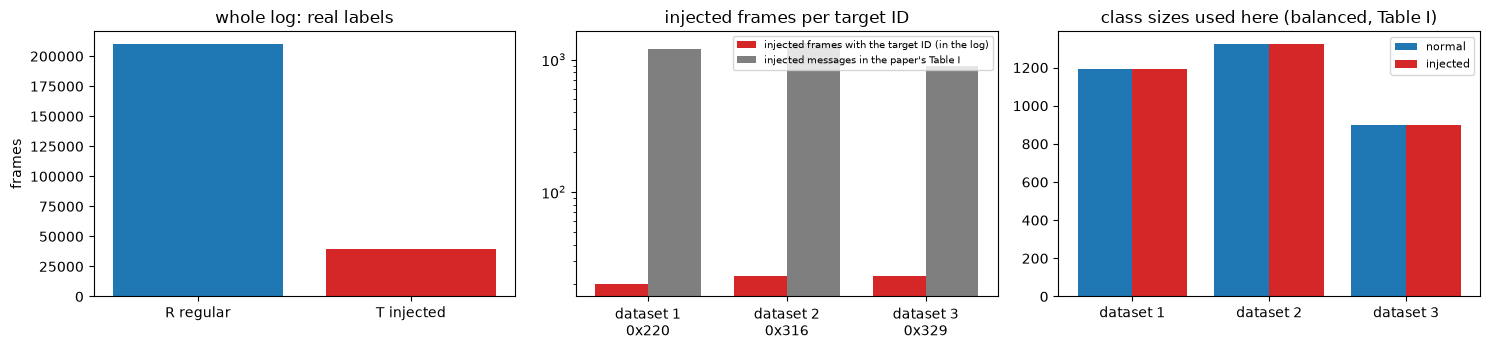

In [9]:
print("raw log shape: (%d frames, 12 fields: timestamp, id, dlc, data0..data7, flag)" % len(TS))
print("original label values and counts:", {"R (regular)": int((~ATT).sum()), "T (injected)": int(ATT.sum())})
for name, D in DATASETS.items():
    print(f"\n{name} ({hex(D['cid'])}): decoded frames {D['Xn'].shape[0] + D['Xa'].shape[0]} x {D['N']} signals; images {D['img'].shape}")
    print("  features:", ", ".join(D["names"]))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].bar(["R regular", "T injected"], [(~ATT).sum(), ATT.sum()], color=["tab:blue", "tab:red"]); ax[0].set_title("whole log: real labels"); ax[0].set_ylabel("frames")
x = np.arange(3); w = 0.38
ax[1].bar(x - w / 2, [(( CID == t[1]) & ATT).sum() for t in TARGETS], w, color="tab:red", label="injected frames with the target ID (in the log)")
ax[1].bar(x + w / 2, [PAPER_T1[t[0]]["att"] for t in TARGETS], w, color="tab:gray", label="injected messages in the paper's Table I")
ax[1].set_xticks(x); ax[1].set_xticklabels([f"{t[0]}\n{hex(t[1])}" for t in TARGETS]); ax[1].set_yscale("log"); ax[1].legend(fontsize=7); ax[1].set_title("injected frames per target ID")
for i, (name, D) in enumerate(DATASETS.items()):
    ax[2].bar([i - 0.2, i + 0.2], [D["n_att"], D["n_att"]], 0.4, color=["tab:blue", "tab:red"], label=["normal", "injected"] if i == 0 else None)
ax[2].set_xticks(range(3)); ax[2].set_xticklabels(list(DATASETS)); ax[2].set_title("class sizes used here (balanced, Table I)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

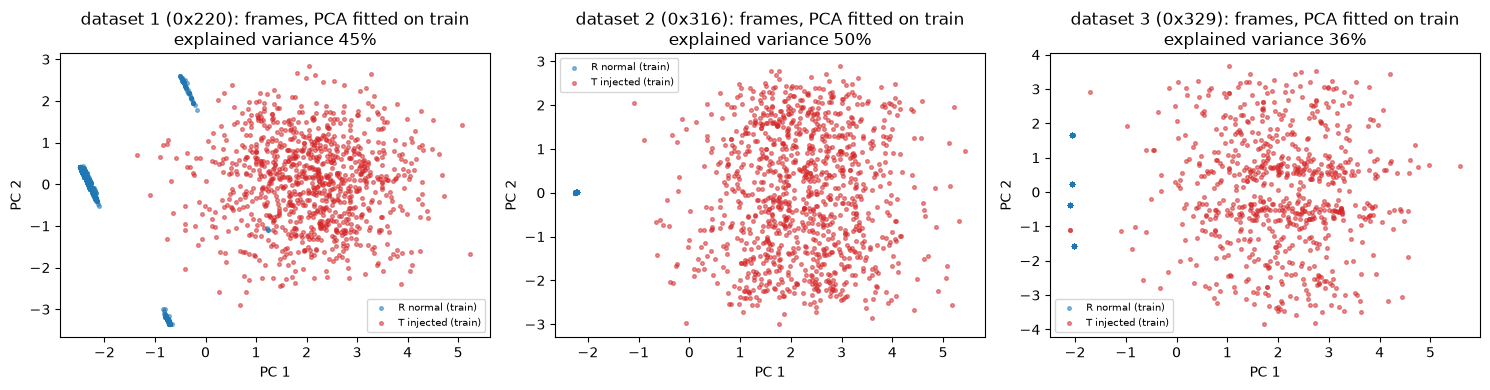

In [10]:
# frame-level PCA of the decoded signals, coloured by the real flag (fitted on the training split of the frames)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, D) in zip(ax, DATASETS.items()):
    X = np.vstack([D["Xn"], D["Xa"]]); y = np.r_[np.zeros(len(D["Xn"]), int), np.ones(len(D["Xa"]), int)]
    itr, ite = train_test_split(np.arange(len(y)), test_size=TEST_SIZE, stratify=y, random_state=SEED)
    sc = StandardScaler().fit(X[itr]); pca = PCA(n_components=2, random_state=SEED).fit(sc.transform(X[itr]))
    Z = pca.transform(sc.transform(X))
    for lab, col, txt in [(0, "tab:blue", "R normal"), (1, "tab:red", "T injected")]:
        m = itr[y[itr] == lab]; a.scatter(Z[m, 0], Z[m, 1], s=7, alpha=.5, c=col, label=txt + " (train)")
    a.set_title(f"{name} ({hex(D['cid'])}): frames, PCA fitted on train\nexplained variance {pca.explained_variance_ratio_.sum():.0%}"); a.legend(fontsize=7)
    a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
plt.tight_layout(); plt.show()

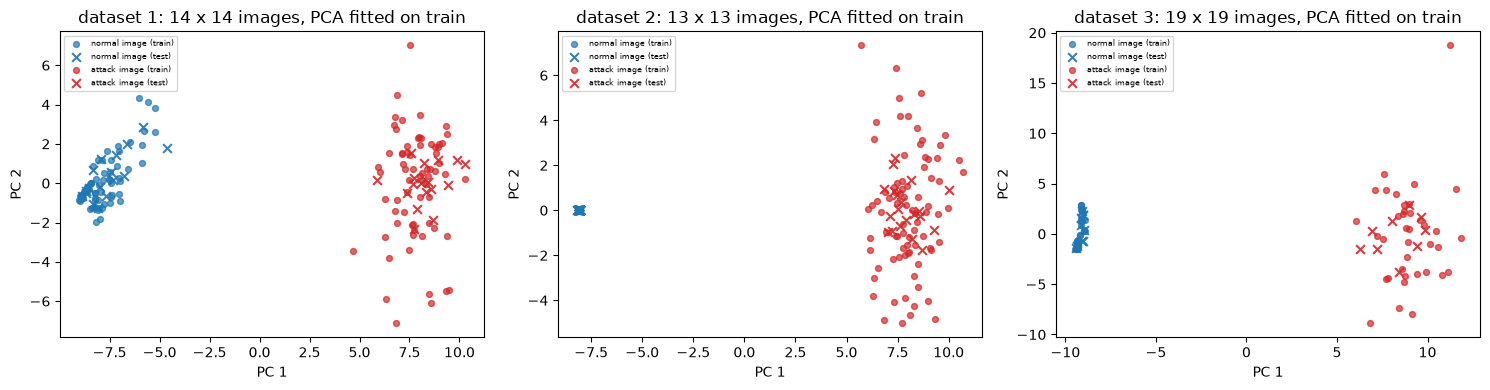

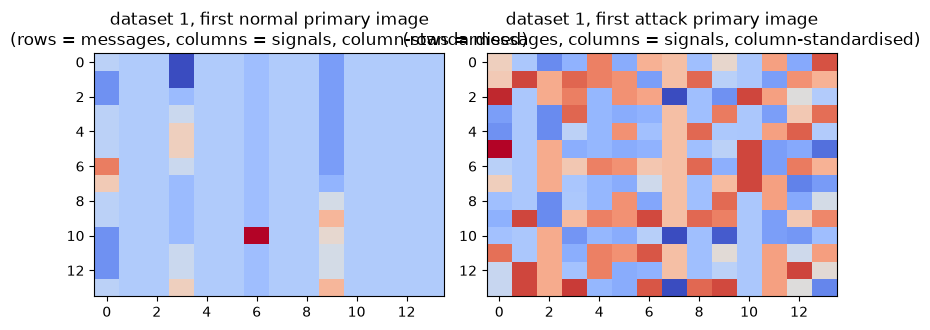

In [11]:
# image-level PCA of the primary N x N CAN images (flattened), coloured by label; fitted on the training split of the images
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, D) in zip(ax, DATASETS.items()):
    X = D["img"].reshape(len(D["y"]), -1); y = D["y"]
    itr, ite = train_test_split(np.arange(len(y)), test_size=TEST_SIZE, stratify=y, random_state=SEED)
    sc = StandardScaler().fit(X[itr]); pca = PCA(n_components=2, random_state=SEED).fit(sc.transform(X[itr]))
    Z = pca.transform(sc.transform(X))
    for lab, col, txt in [(0, "tab:blue", "normal image"), (1, "tab:red", "attack image")]:
        m = itr[y[itr] == lab]; a.scatter(Z[m, 0], Z[m, 1], s=18, alpha=.7, c=col, label=txt + " (train)")
        m = ite[y[ite] == lab]; a.scatter(Z[m, 0], Z[m, 1], s=40, alpha=.9, c=col, marker="x", label=txt + " (test)")
    a.set_title(f"{name}: {D['N']} x {D['N']} images, PCA fitted on train"); a.legend(fontsize=6); a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
plt.tight_layout(); plt.show()
D0 = DATASETS["dataset 1"]
fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
for a, (lab, txt) in zip(ax, [(0, "normal"), (1, "attack")]):
    im = D0["img"][np.where(D0["y"] == lab)[0][0]]
    a.imshow((im - im.mean(0)) / (im.std(0) + 1e-9), cmap="coolwarm", aspect="auto"); a.set_title(f"dataset 1, first {txt} primary image\n(rows = messages, columns = signals, column-standardised)")
plt.tight_layout(); plt.show()

In the frame-level plots the regular frames occupy a very small region (physical signals change slowly and several signals are constant) while the injected frames form a broad cloud (random bytes decoded into signals), so the two classes are separated in two dimensions already. This is expected: the fuzzy attack is crude. A classifier has to be much worse than a simple rule to fail here.

## 4. The classical feature extractor, 8 x 6 binary images and label embedding

For every random split the network below is trained on the **training images only** (labels attack / normal) and then used as a feature extractor:
the output of its 64-unit layer is min-max scaled per image to [0, 1], read as an 8 x 8 map, average-pooled to 8 x 6 and thresholded at 0.5.
Two more columns hold the label (8 x 2 ones for attack, zeros for normal), giving the 8 x 8 = 64 visible bits of the RBM. Bits are numbered column by column, so the **last 16 visible units are the label pixels**.

extractor trained in 18.1 s; head accuracy train 1.000, test 1.000; binary images (136, 8, 6), with labels (136, 64)


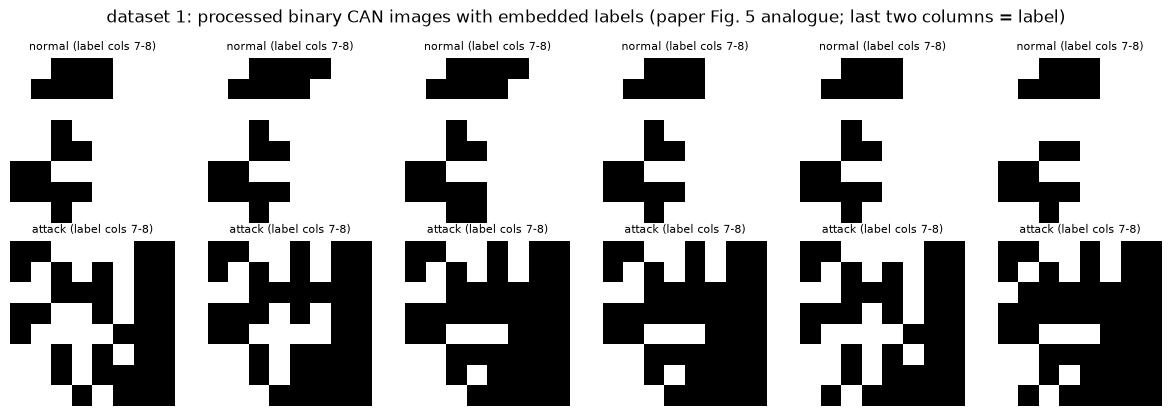

In [12]:
class Extractor(nn.Module):
    """The public script's network: Flatten - Dense(100, relu) - Dense(64) - Dense(16) - Dense(1); the 64-unit layer is the 8 x 8 code."""
    def __init__(self, n_in):
        super().__init__()
        self.f1, self.f2, self.f3, self.f4 = nn.Linear(n_in, 100), nn.Linear(100, 64), nn.Linear(64, 16), nn.Linear(16, 1)
    def features(self, x):
        return self.f2(torch.relu(self.f1(x.flatten(1))))
    def forward(self, x):
        return self.f4(self.f3(self.features(x))).squeeze(1)

class FittedExtractor:
    def __init__(self, imgs, y, seed):
        n, N = imgs.shape[0], imgs.shape[1]
        frames = imgs.reshape(-1, N)
        self.ss = StandardScaler().fit(frames); self.mm = MinMaxScaler().fit(self.ss.transform(frames))     # fitted on the training images only
        X = torch.tensor(self.scale(imgs), dtype=torch.float32); Y = torch.tensor(y, dtype=torch.float32)
        torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
        self.net = Extractor(N * N); opt = torch.optim.Adam(self.net.parameters(), lr=NN_LR); lossf = nn.BCEWithLogitsLoss()
        for ep in range(NN_EPOCHS):
            perm = torch.randperm(n, generator=g)
            for i in range(0, n, NN_BATCH):
                b = perm[i:i + NN_BATCH]; opt.zero_grad(); lossf(self.net(X[b]), Y[b]).backward(); opt.step()
    def scale(self, imgs):
        N = imgs.shape[1]
        return self.mm.transform(self.ss.transform(imgs.reshape(-1, N))).reshape(imgs.shape)
    def head_predict(self, imgs):
        with torch.no_grad():
            return (self.net(torch.tensor(self.scale(imgs), dtype=torch.float32)) > 0).numpy().astype(int)
    def bits(self, imgs):
        """(n, 8, 6) binary images and the (n, 64) per-image min-max scaled code."""
        with torch.no_grad():
            f = self.net.features(torch.tensor(self.scale(imgs), dtype=torch.float32)).numpy()
        lo, hi = f.min(1, keepdims=True), f.max(1, keepdims=True)
        f01 = (f - lo) / np.maximum(hi - lo, 1e-12)
        pooled = F.adaptive_avg_pool2d(torch.tensor(f01.reshape(-1, 1, 8, 8), dtype=torch.float32), (8, 6)).numpy()[:, 0]    # CHOICE: resize = average pooling
        return (pooled > 0.5).astype(np.float32), f01

def embed_label(bits, y):
    """(n, 8, 6) bits + (n,) labels -> (n, 64) visible vectors; column-major order, last 16 entries = the two label columns."""
    img = np.concatenate([bits, np.broadcast_to(np.asarray(y, np.float32)[:, None, None], (len(bits), 8, 2))], axis=2)   # (n, 8, 8)
    return img.transpose(0, 2, 1).reshape(len(img), 64)

def flat_bits(bits):
    return bits.transpose(0, 2, 1).reshape(len(bits), 48)

# demonstration on one split of dataset 1
D = DATASETS["dataset 1"]; y = D["y"]
itr, ite = train_test_split(np.arange(len(y)), test_size=TEST_SIZE, stratify=y, random_state=SEED)
t0 = time.time(); ex_demo = FittedExtractor(D["img"][itr], y[itr], SEED)
Btr, _ = ex_demo.bits(D["img"][itr]); Bte, _ = ex_demo.bits(D["img"][ite])
print(f"extractor trained in {time.time()-t0:.1f} s; head accuracy train {np.mean(ex_demo.head_predict(D['img'][itr]) == y[itr]):.3f}, "
      f"test {np.mean(ex_demo.head_predict(D['img'][ite]) == y[ite]):.3f}; binary images {Btr.shape}, with labels {embed_label(Btr, y[itr]).shape}")
fig, ax = plt.subplots(2, 6, figsize=(12, 4.2))
for r, lab in enumerate([0, 1]):
    for c in range(6):
        i = np.where(y[itr] == lab)[0][c]
        ax[r, c].imshow(embed_label(Btr[i:i + 1], [lab])[0].reshape(8, 8).T, cmap="gray_r"); ax[r, c].axis("off")
        ax[r, c].set_title(("normal" if lab == 0 else "attack") + " (label cols 7-8)", fontsize=8)
plt.suptitle("dataset 1: processed binary CAN images with embedded labels (paper Fig. 5 analogue; last two columns = label)"); plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

**What is sampled.** Training and reconstruction only ever sample one RBM layer given the other. For hidden units `h` given the visible vector `v` the paper's QUBO
(Eq. 6 with the RBM energy of Eq. 3, evaluated at the clamped layer) is

`E(h) = sum_j c_j h_j`,  `c_j = -(b_j + sum_i v_i w_ij)`,

a QUBO **without any quadratic term**: the 64 binary variables do not interact (the same holds for `v` given `h`). Its ground state is simply `h_j = 1 iff c_j < 0`.
An annealer therefore runs 64 *independent* qubits, and the quantum computation is exactly simulable.

**The annealing circuit** (closed system, one qubit per variable, `|1>` = variable 1). With `H(s) = (1 - s) Gamma (-X) + s * c (1 - Z) / 2` and `s = t / T`, the evolution from `|+>` is
Trotterised with the symmetric (Strang) splitting `RX(phi_k / 2) RZ(-dt s_k c) RX(phi_k / 2)`, `phi_k = -2 dt Gamma (1 - s_k)`, `dt = T / K`, `s_k = (k + 1/2) / K`; neighbouring half-steps are merged.
The qubits are measured in the Z basis: variable = 1 with probability `p1(c)`. Because the qubits are independent, the 64-qubit device needs no 2^64 state vector: `p1` depends only on the (rescaled) field of one qubit.
D-Wave rescales the problem coefficients into the hardware range; this is imitated by multiplying all `c_j` of one QUBO by `min(1, H_RANGE / max_j |c_j|)` before the anneal (`# CHOICE`).

The checks below (1) run the circuit as a PennyLane QNode on 6 qubits, (2) compare it with an independent NumPy gate-by-gate simulator (the one used for the 64 qubits and for the lookup table), and (3) draw the executed circuit.

In [13]:
GAMMA = 1.0
def n_trotter(T):
    return max(TROTTER_MIN, int(round(2.5 * T)))

def schedule(T, K):
    """RX angles (K + 1 layers, half steps merged) and RZ angle factors (K layers: angle = rz[k] * c_j) of the Strang-split anneal."""
    dt = T / K
    s = (np.arange(K) + 0.5) / K
    phi = -2 * dt * GAMMA * (1 - s)
    rx = np.empty(K + 1); rx[0] = phi[0] / 2; rx[K] = phi[K - 1] / 2; rx[1:K] = (phi[:-1] + phi[1:]) / 2
    return rx, -dt * s

def make_qnode(n, T, K, joint=False):
    dev = qml.device("default.qubit", wires=n)
    rx, rz = schedule(T, K)
    @qml.qnode(dev)
    def annealer(c):
        for w in range(n): qml.Hadamard(wires=w)                       # |0> -> |+>, ground state of the driver -X
        for k in range(K):
            for w in range(n): qml.RX(rx[k], wires=w)
            for w in range(n): qml.RZ(rz[k] * c[w], wires=w)           # problem Hamiltonian, one field per qubit
        for w in range(n): qml.RX(rx[K], wires=w)
        if joint:
            return qml.probs(wires=range(n))
        return [qml.probs(wires=w) for w in range(n)]                  # Z-basis read-out of every qubit
    return annealer

def p1_numpy(c, T, K):
    """Independent NumPy gate-by-gate simulation of the same gate list; returns P(variable = 1) for every field in c (any shape)."""
    c = np.asarray(c, float); rx, rz = schedule(T, K)
    psi = np.tile(np.array([1, 1], complex) / np.sqrt(2), c.shape + (1,))      # H|0> = |+>
    def RX(psi, phi):
        co, si = np.cos(phi / 2), np.sin(phi / 2); a, b = psi[..., 0], psi[..., 1]
        return np.stack([co * a - 1j * si * b, -1j * si * a + co * b], -1)
    for k in range(K):
        psi = RX(psi, rx[k])
        ang = rz[k] * c                                                         # RZ(ang) = diag(e^{-i ang/2}, e^{+i ang/2})
        psi = psi * np.stack([np.exp(-1j * ang / 2), np.exp(1j * ang / 2)], -1)
    psi = RX(psi, rx[K])
    return np.abs(psi[..., 1]) ** 2

K0 = n_trotter(ANNEAL_T)
qn6 = make_qnode(6, ANNEAL_T, K0); qn6_joint = make_qnode(6, ANNEAL_T, K0, joint=True)
r = np.random.default_rng(SEED)
worst, worst_prod = 0.0, 0.0
for trial in range(20):
    c6 = r.uniform(-H_RANGE, H_RANGE, 6)
    out = qn6(c6)                                              # list of 6 single-qubit probability vectors
    marg = np.array([o[1] for o in out]); ref = p1_numpy(c6, ANNEAL_T, K0)
    worst = max(worst, np.abs(marg - ref).max())
    jp = np.asarray(qn6_joint(c6))                             # 64 joint outcome probabilities
    prod = np.ones(64)
    for idx in range(64):
        for w in range(6):
            bit = (idx >> (5 - w)) & 1
            prod[idx] *= ref[w] if bit else 1 - ref[w]
    worst_prod = max(worst_prod, np.abs(jp - prod).max())
print(f"PennyLane QNode (6 qubits, K = {K0} Trotter steps) vs NumPy gate-list simulator: max |difference| = {worst:.2e} over 20 random field vectors")
print(f"joint 6-qubit distribution vs product of the NumPy single-qubit probabilities: max |difference| = {worst_prod:.2e} (no entanglement is generated)")
assert worst < 1e-9 and worst_prod < 1e-9

PennyLane QNode (6 qubits, K = 25 Trotter steps) vs NumPy gate-list simulator: max |difference| = 3.77e-15 over 20 random field vectors
joint 6-qubit distribution vs product of the NumPy single-qubit probabilities: max |difference| = 2.22e-15 (no entanglement is generated)


executed 4-qubit circuit: 208 gates = 4 H + 25 x (4 RX + 4 RZ) + 4 RX, measured in the Z basis


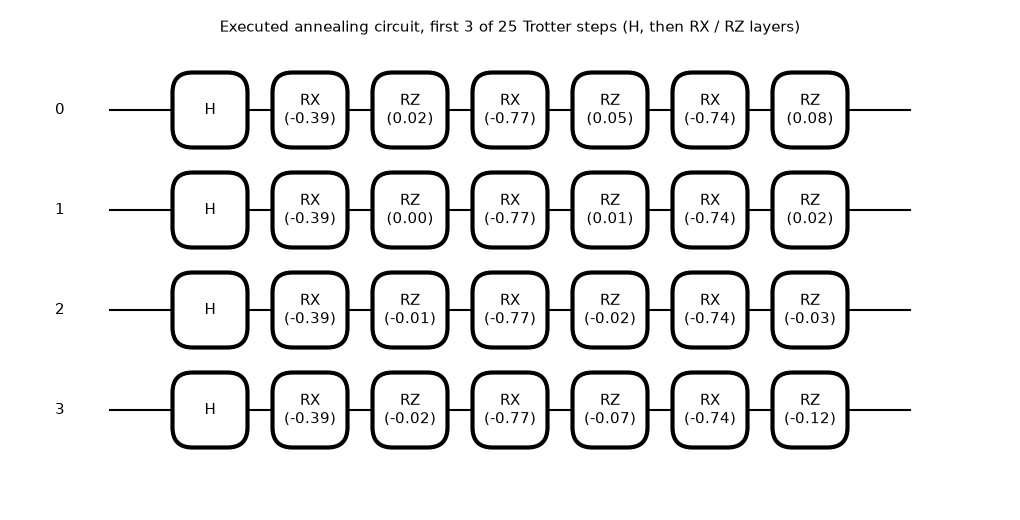

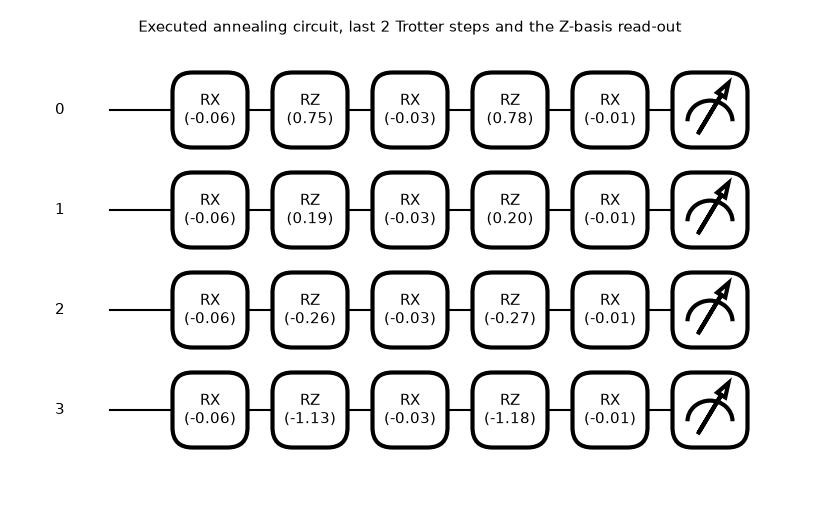

p1 read out from the drawn circuit's fields [0.9975 0.8307 0.0859 0.0011]  (fields c = [-2.  -0.5  0.7  3. ] )


In [14]:
# the executed circuit, drawn from the real QNode tape (4 qubits): first 3 and last 2 Trotter steps; the middle steps are the same blocks with other angles
c4 = np.array([-2.0, -0.5, 0.7, 3.0]); n4 = 4
qn4 = make_qnode(n4, ANNEAL_T, K0)
tape = qml.workflow.construct_tape(qn4)(c4)
ops = tape.operations
print(f"executed 4-qubit circuit: {len(ops)} gates = {n4} H + {K0} x ({n4} RX + {n4} RZ) + {n4} RX, measured in the Z basis")
head = qml.tape.QuantumScript(ops[:n4 * (1 + 2 * 3)], [])
tail = qml.tape.QuantumScript(ops[-n4 * 5:], tape.measurements)
fig, ax = qml.drawer.tape_mpl(head, decimals=2, fontsize=11); fig.suptitle(f"Executed annealing circuit, first 3 of {K0} Trotter steps (H, then RX / RZ layers)", fontsize=11); plt.show()
fig, ax = qml.drawer.tape_mpl(tail, decimals=2, fontsize=11); fig.suptitle("Executed annealing circuit, last 2 Trotter steps and the Z-basis read-out", fontsize=11); plt.show()
print("p1 read out from the drawn circuit's fields", np.round([o[1] for o in qn4(c4)], 4), " (fields c =", c4, ")")

qubits: 64 (one per hidden unit, or one per visible unit when the visible layer is sampled), circuit depth: 52, gates: 3328
free trainable gate parameters in the circuit: 0 (the angles are the fixed schedule times the field c_j of the RBM; the RBM itself has 4224 trainable parameters: 64x64 weights + 64 + 64 biases, as in the paper)
Assumptions where the paper is silent: closed-system transverse-field annealing, Gamma = 1, linear schedule, anneal time T = 10.0 (K = 25 Trotter steps, second-order splitting), coefficients rescaled into [-4.0, 4.0], one read per sample, no embedding or chain noise.
lookup-table interpolation error 2.6e-06; Trotter error (K = 25 vs 200) 1.2e-03


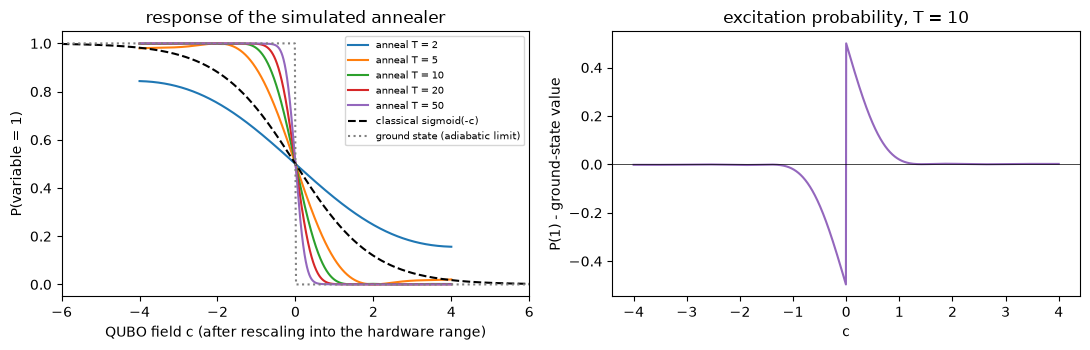

In [15]:
# the 64-qubit annealer of the 64-unit layer: resources of the real circuit (built, not state-vector simulated; the qubits are independent)
n64 = 64; qn64 = make_qnode(n64, ANNEAL_T, K0)
c64 = np.random.default_rng(SEED).uniform(-H_RANGE, H_RANGE, n64)
spec = qml.specs(qn64)(c64)
res = spec["resources"]
n_layer_params = N_VISIBLE * N_HIDDEN + N_VISIBLE + N_HIDDEN
print(f"qubits: {n64} (one per hidden unit, or one per visible unit when the visible layer is sampled), circuit depth: {res.depth}, gates: {res.num_gates}")
print(f"free trainable gate parameters in the circuit: 0 (the angles are the fixed schedule times the field c_j of the RBM; the RBM itself has {n_layer_params} trainable parameters: "
      f"{N_VISIBLE}x{N_HIDDEN} weights + {N_VISIBLE} + {N_HIDDEN} biases, as in the paper)")
print("Assumptions where the paper is silent: closed-system transverse-field annealing, Gamma = 1, linear schedule, anneal time T =", ANNEAL_T,
      f"(K = {K0} Trotter steps, second-order splitting), coefficients rescaled into [-{H_RANGE}, {H_RANGE}], one read per sample, no embedding or chain noise.")

# lookup table of the response function p1(c): same NumPy gate-list simulator as checked above, on a fine grid
GRID = np.linspace(-H_RANGE, H_RANGE, 1601)
def build_table(T):
    return p1_numpy(GRID, T, n_trotter(T))
TABLES = {T: build_table(T) for T in sorted(set(T_SWEEP + [ANNEAL_T]))}
err_interp = np.abs(np.interp(c64, GRID, TABLES[ANNEAL_T]) - p1_numpy(c64, ANNEAL_T, K0)).max()
c_fine = np.linspace(-H_RANGE, H_RANGE, 801)
conv = np.abs(p1_numpy(c_fine, ANNEAL_T, K0) - p1_numpy(c_fine, ANNEAL_T, 8 * K0)).max()
print(f"lookup-table interpolation error {err_interp:.1e}; Trotter error (K = {K0} vs {8*K0}) {conv:.1e}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
cc = np.linspace(-6, 6, 400)
for T in sorted(TABLES):
    ax[0].plot(GRID, TABLES[T], label=f"anneal T = {T:g}")
ax[0].plot(cc, 1 / (1 + np.exp(cc)), "k--", label="classical sigmoid(-c)")
ax[0].plot(cc, (cc < 0).astype(float), color="gray", ls=":", label="ground state (adiabatic limit)")
ax[0].set_xlabel("QUBO field c (after rescaling into the hardware range)"); ax[0].set_ylabel("P(variable = 1)"); ax[0].set_xlim(-6, 6); ax[0].legend(fontsize=7); ax[0].set_title("response of the simulated annealer")
ax[1].plot(GRID, TABLES[ANNEAL_T] - np.where(GRID < 0, 1.0, 0.0), color="tab:purple"); ax[1].axhline(0, color="k", lw=.5)
ax[1].set_xlabel("c"); ax[1].set_ylabel("P(1) - ground-state value"); ax[1].set_title(f"excitation probability, T = {ANNEAL_T:g}")
plt.tight_layout(); plt.show()

## 5. The RBM, its samplers and the conditional-layer QUBO

An RBM has energy `E(v, h) = -a.v - b.h - v^T W h`. The three samplers differ only in how a layer is drawn from the activation `a_j = bias_j + sum_i x_i w_ij` of the other layer:

| sampler | draw of unit j | what it stands for |
|---|---|---|
| `classical` | `Bernoulli(sigmoid(a_j))` | contrastive divergence, the paper's classical-only framework |
| `qa` | rescale the QUBO fields `c = -a`, then `Bernoulli(p1(c_j))` from the simulated annealer | the paper's quantum RBM (D-Wave replaced by the circuit above) |
| `ground` | `1 iff a_j > 0` | the adiabatic limit = exact ground state of the QUBO; also what a perfect annealer returns |

Training follows the public script: **one training image per "epoch"** (cyclic order), `h ~ p(h|v)`, `v' ~ p(v|h)`, `h' ~ p(h|v')`,
`W += lr (v h^T - v' h'^T)`, `a += lr (v - v')`, `b += lr (h - h')`. Reconstruction of a test image: label bits random, one pass `v -> h -> v'`, label = majority of the 16 reconstructed label bits.

In [16]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

class LayerSampler:
    """Draw a binary layer from activations a of shape (n_rows, m); rows are independent QUBOs."""
    def __init__(self, kind, table=None):
        self.kind, self.table = kind, table
    def __call__(self, a, rg):
        if self.kind == "classical":
            return (rg.random(a.shape) < sigmoid(a)).astype(np.float64)
        if self.kind == "ground":
            return (a > 0).astype(np.float64)
        c = -a                                                           # QUBO linear coefficients
        scale = np.minimum(1.0, H_RANGE / np.maximum(np.abs(c).max(axis=1, keepdims=True), 1e-12))   # CHOICE: hardware auto-scaling
        p1 = np.interp((c * scale).ravel(), GRID, self.table).reshape(c.shape)
        return (rg.random(a.shape) < p1).astype(np.float64)

def make_sampler(kind, T=None):
    return LayerSampler(kind, TABLES[ANNEAL_T if T is None else T] if kind == "qa" else None)

def train_rbm(V, kind, n_updates, lr, seed, T=None, curve=False):
    """Public-script training: one image per update, cyclic order of a seeded shuffle; weights and biases U(-1, 1)."""
    S = make_sampler(kind, T); rg = np.random.default_rng(seed)
    W = rg.random((N_VISIBLE, N_HIDDEN)) * 2 - 1; a = rg.random(N_VISIBLE) * 2 - 1; b = rg.random(N_HIDDEN) * 2 - 1   # init identical for all samplers
    order = rg.permutation(len(V)); rg = np.random.default_rng(seed + 1)
    err = []
    for t in range(n_updates):
        v = V[order[t % len(V)]][None, :]
        h = S(b + v @ W, rg)
        v1 = S(a + h @ W.T, rg)
        h1 = S(b + v1 @ W, rg)
        W += lr * (v.T @ h - v1.T @ h1); a += lr * (v - v1)[0]; b += lr * (h - h1)[0]
        if curve: err.append(float(((v - v1) ** 2).sum()))
    return (W, a, b, err) if curve else (W, a, b)

def predict_rbm(params, kind, bits, seed, T=None):
    """Label bits replaced by random bits, one reconstruction, majority of the 16 label bits (1 = attack)."""
    W, a, b = params; S = make_sampler(kind, T); rg = np.random.default_rng(seed + 7)
    V = np.concatenate([flat_bits(bits).astype(np.float64), rg.integers(0, 2, (len(bits), 16)).astype(np.float64)], axis=1)
    h = S(b + V @ W, rg); V1 = S(a + h @ W.T, rg)
    return (V1[:, 48:].mean(axis=1) > 0.5).astype(int)

def metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    tp, tn = int(((p == 1) & (y == 1)).sum()), int(((p == 0) & (y == 0)).sum()); fp, fn = int(((p == 1) & (y == 0)).sum()), int(((p == 0) & (y == 1)).sum())
    acc = (tp + tn) / len(y); prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1); f1 = 2 * prec * rec / max(prec + rec, 1e-12)
    return dict(acc=100 * acc, prec=100 * prec, rec=100 * rec, f1=100 * f1, tp=tp, tn=tn, fp=fp, fn=fn)

# --- check 1: the conditional QUBO has no quadratic terms, its exact ground state is the threshold rule, and simulated annealing finds it
Wd, ad, bd = train_rbm(embed_label(Btr, y[itr]), "classical", 300, 0.05, SEED)
rg = np.random.default_rng(SEED); agree, tested = 0, 0
for i in range(60):
    v = embed_label(Bte[i % len(Bte): i % len(Bte) + 1], [y[ite][i % len(ite)]])[0]
    act = bd + v @ Wd                                               # activations of the 64 hidden units
    bqm = dimod.BinaryQuadraticModel({j: -float(act[j]) for j in range(64)}, {}, 0.0, "BINARY")          # E(h) = -sum_j act_j h_j
    sa = SimulatedAnnealingSampler().sample(bqm, num_reads=1, seed=int(rg.integers(1 << 30))).first.sample
    agree += int(np.sum([sa[j] == int(act[j] > 0) for j in range(64)])); tested += 64
print(f"conditional QUBO: {len(bqm.quadratic)} quadratic terms; simulated annealing agrees with the threshold ground state on {100*agree/tested:.1f} % of {tested} variables")
toy = dimod.BinaryQuadraticModel({j: -float(act[j]) for j in range(12)}, {}, 0.0, "BINARY")
gs = dimod.ExactSolver().sample(toy).first.sample
print("exact enumeration on 12 variables equals the threshold rule:", all(gs[j] == int(act[j] > 0) for j in range(12)))

conditional QUBO: 0 quadratic terms; simulated annealing agrees with the threshold ground state on 99.9 % of 3840 variables
exact enumeration on 12 variables equals the threshold rule: True


## 6. Training and evaluation: protocol A (the paper's protocol, repeated over seeds)

For every dataset and every seed:
1. stratified 80 / 20 split of the images; the training part is split again 75 / 25 into *fit* and *validation* images;
2. a first extractor is trained on *fit*, the RBM hyper-parameters (number of updates, learning rate from the grid) of every sampler are chosen on the *validation* images (never seen by the extractor, just like the test images);
3. a second extractor is trained on the whole training part, every RBM is trained with the chosen hyper-parameters, and everything is evaluated **once** on the test images.

Two RBM settings are reported: the public script's (50 updates, lr 0.1) and the validation-tuned one. Baselines see the identical 8 x 6 binary images (and the 64-value code).
Attack is the positive class for recall, as in the paper. Test sets are tiny (one image is 2 to 5 accuracy points), hence the repeated seeds.

In [17]:
KINDS = [("classical", "CRBM (classical CD)"), ("qa", "QRBM (simulated QA)"), ("ground", "RBM ground-state sampler")]
ROWS, CACHE, CURVES, SELECTED = [], {}, {}, {}

def add_row(protocol, ds, seed, model, setting, y, p, secs, **extra):
    ROWS.append(dict(protocol=protocol, dataset=ds, seed=seed, model=model, setting=setting, n_test=len(y), secs=secs, **metrics(y, p), **extra))

def tune_rbm(kind, Bfit, yfit, Bval, yval, seed):
    V = embed_label(Bfit, yfit); best = None; table = {}
    for upd in GRID_UPDATES:
        for lr in GRID_LR:
            prm = train_rbm(V, kind, upd, lr, seed)
            acc = float(np.mean(predict_rbm(prm, kind, Bval, seed) == yval)); table[(upd, lr)] = acc
            if best is None or acc > best[0]:
                best = (acc, upd, lr)
    return best[1], best[2], table

def pipeline_A(ds, seed):
    D = DATASETS[ds]; imgs, y = D["img"], D["y"]
    idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=TEST_SIZE, stratify=y, random_state=seed)
    idx_fit, idx_val = train_test_split(idx_tr, test_size=VAL_FRAC, stratify=y[idx_tr], random_state=seed)
    ex1 = FittedExtractor(imgs[idx_fit], y[idx_fit], seed)
    Bfit, _ = ex1.bits(imgs[idx_fit]); Bval, _ = ex1.bits(imgs[idx_val])
    sel = {k: tune_rbm(k, Bfit, y[idx_fit], Bval, y[idx_val], seed) for k, _ in KINDS}
    SELECTED[(ds, seed)] = {k: (v[0], v[1]) for k, v in sel.items()}
    t0 = time.time(); ex = FittedExtractor(imgs[idx_tr], y[idx_tr], seed); t_ex = time.time() - t0
    Btr, Ftr = ex.bits(imgs[idx_tr]); Bte, Fte = ex.bits(imgs[idx_te]); ytr, yte = y[idx_tr], y[idx_te]
    CACHE[(ds, seed)] = (Btr, ytr, Bte, yte)
    t0 = time.time(); p = ex.head_predict(imgs[idx_te]); add_row("A", ds, seed, "extractor network (head)", "-", yte, p, t_ex + time.time() - t0)
    for name, mk in [("RandomForest (48 bits)", lambda: RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1)),
                     ("SVC rbf (48 bits)", lambda: SVC(C=1.0, kernel="rbf", gamma="scale"))]:
        t0 = time.time(); m = mk().fit(flat_bits(Btr), ytr); add_row("A", ds, seed, name, "-", yte, m.predict(flat_bits(Bte)), time.time() - t0)
    for name, mk in [("RandomForest (64-value code)", lambda: RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1)),
                     ("SVC rbf (64-value code)", lambda: SVC(C=1.0, kernel="rbf", gamma="scale"))]:
        t0 = time.time(); m = mk().fit(Ftr, ytr); add_row("A", ds, seed, name, "-", yte, m.predict(Fte), time.time() - t0)
    Vtr = embed_label(Btr, ytr)
    for k, label in KINDS:
        for setting, (upd, lr) in [("script (50 upd, lr 0.1)", (SCRIPT_UPDATES, SCRIPT_LR)), ("tuned on validation", sel[k][:2])]:
            t0 = time.time(); out = train_rbm(Vtr, k, upd, lr, seed, curve=True); prm = out[:3]
            p = predict_rbm(prm, k, Bte, seed)
            add_row("A", ds, seed, label, setting, yte, p, time.time() - t0, updates=upd, lr=lr)
            if setting.startswith("tuned"): CURVES[(ds, seed, k)] = out[3]

t_start = time.time()
for ds in DATASETS:
    for seed in range(N_SEEDS):
        pipeline_A(ds, seed)
    print(f"{ds}: {N_SEEDS} seeds done ({time.time() - t_start:.0f} s cumulative)", flush=True)
RA = pd.DataFrame(ROWS)
print("protocol A finished in %.1f min, %d result rows" % ((time.time() - t_start) / 60, len(RA)))

dataset 1: 10 seeds done (251 s cumulative)


dataset 2: 10 seeds done (577 s cumulative)


dataset 3: 10 seeds done (814 s cumulative)


protocol A finished in 13.6 min, 330 result rows


In [18]:
def summary(R, protocol):
    G = R[R.protocol == protocol].groupby(["dataset", "model", "setting"], sort=False)
    S = G[["acc", "prec", "rec", "f1", "secs"]].agg(["mean", "std"]).round(1)
    S.columns = [f"{a}_{b}" for a, b in S.columns]
    S["n_test_per_seed"] = G["n_test"].first().astype(int)
    return S.reset_index()
SA = summary(RA, "A")
display(SA[["dataset", "model", "setting", "n_test_per_seed", "acc_mean", "acc_std", "rec_mean", "rec_std", "prec_mean", "f1_mean", "secs_mean"]])
print("selected (updates, lr) of the validation-tuned RBMs, counts over datasets and seeds:")
sel_df = pd.DataFrame([dict(dataset=d, seed=s, sampler=k, updates=u, lr=l) for (d, s), v in SELECTED.items() for k, (u, l) in v.items()])
display(sel_df.groupby(["sampler", "updates", "lr"]).size().unstack(0).fillna(0).astype(int))

,dataset,model,setting,n_test_per_seed,acc_mean,acc_std,rec_mean,rec_std,prec_mean,f1_mean,secs_mean
0,dataset 1,extractor network (head),-,34,100.0,0.0,100.0,0.0,100.0,100.0,10.6
1,dataset 1,RandomForest (48 bits),-,34,100.0,0.0,100.0,0.0,100.0,100.0,1.1
2,dataset 1,SVC rbf (48 bits),-,34,100.0,0.0,100.0,0.0,100.0,100.0,0.0
3,dataset 1,RandomForest (64-value code),-,34,100.0,0.0,100.0,0.0,100.0,100.0,1.1
4,dataset 1,SVC rbf (64-value code),-,34,100.0,0.0,100.0,0.0,100.0,100.0,0.0
5,dataset 1,CRBM (classical CD),"script (50 upd, lr 0.1)",34,100.0,0.0,100.0,0.0,100.0,100.0,0.0
6,dataset 1,CRBM (classical CD),tuned on validation,34,99.7,0.9,99.4,1.9,100.0,99.7,0.0
7,dataset 1,QRBM (simulated QA),"script (50 upd, lr 0.1)",34,99.7,0.9,100.0,0.0,99.4,99.7,0.0
8,dataset 1,QRBM (simulated QA),tuned on validation,34,99.1,1.4,99.4,1.9,98.9,99.1,0.1
9,dataset 1,RBM ground-state sampler,"script (50 upd, lr 0.1)",34,94.1,6.8,99.4,1.9,91.2,94.8,0.0


selected (updates, lr) of the validation-tuned RBMs, counts over datasets and seeds:


sampler       classical  ground  qa
updates lr                         
50      0.02         16       4  19
        0.10         11      17   9
300     0.02          1       1   0
        0.10          2       7   2
1500    0.10          0       1   0

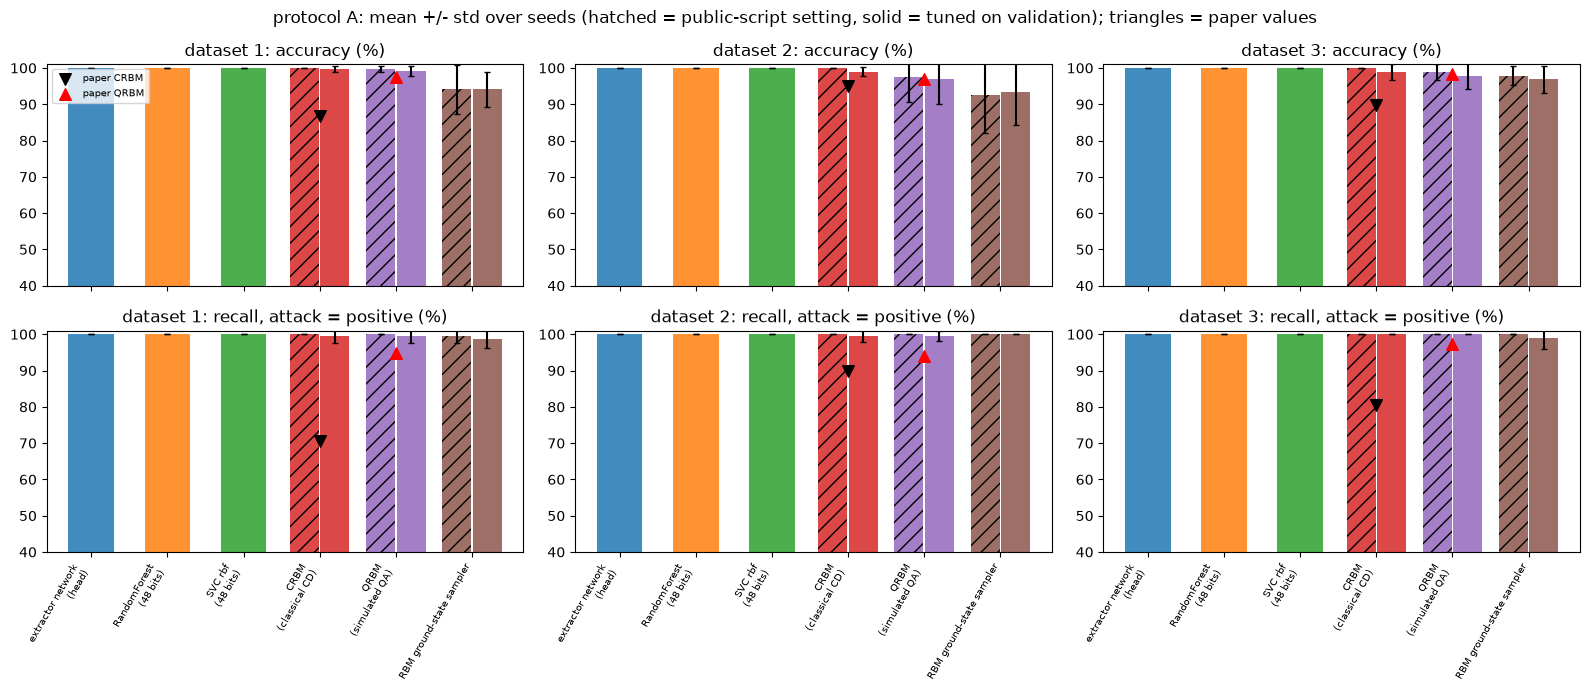

In [19]:
# bar chart: accuracy and recall of every model per dataset, with the paper's RBM values as markers
models = ["extractor network (head)", "RandomForest (48 bits)", "SVC rbf (48 bits)", "CRBM (classical CD)", "QRBM (simulated QA)", "RBM ground-state sampler"]
fig, ax = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for j, ds in enumerate(DATASETS):
    for i, (metric, ttl) in enumerate([("acc", "accuracy (%)"), ("rec", "recall, attack = positive (%)")]):
        a = ax[i, j]
        for m_i, m in enumerate(models):
            for setting, hatch, off in ([("script (50 upd, lr 0.1)", "//", -0.2), ("tuned on validation", "", 0.2)] if "RBM" in m else [("-", "", 0.0)]):
                s = RA[(RA.protocol == "A") & (RA.dataset == ds) & (RA.model == m) & (RA.setting == setting)][metric]
                a.bar(m_i + off, s.mean(), 0.38 if "RBM" in m else 0.6, yerr=s.std(), color=f"C{m_i}", hatch=hatch, alpha=.85, capsize=2)
        for key, mk, col in [("CRBM", "v", "k"), ("QRBM", "^", "red")]:
            a.scatter([models.index("CRBM (classical CD)" if key == "CRBM" else "QRBM (simulated QA)")], [PAPER[(ds, key)][i]], marker=mk, c=col, s=70, zorder=5, label=f"paper {key}")
        a.set_title(f"{ds}: {ttl}"); a.set_ylim(40, 101); a.set_xticks(range(len(models))); a.set_xticklabels([m.replace(" (", "\n(") for m in models], rotation=60, fontsize=7, ha="right")
        if i == 0 and j == 0: a.legend(fontsize=7)
plt.suptitle("protocol A: mean +/- std over seeds (hatched = public-script setting, solid = tuned on validation); triangles = paper values"); plt.tight_layout(); plt.show()

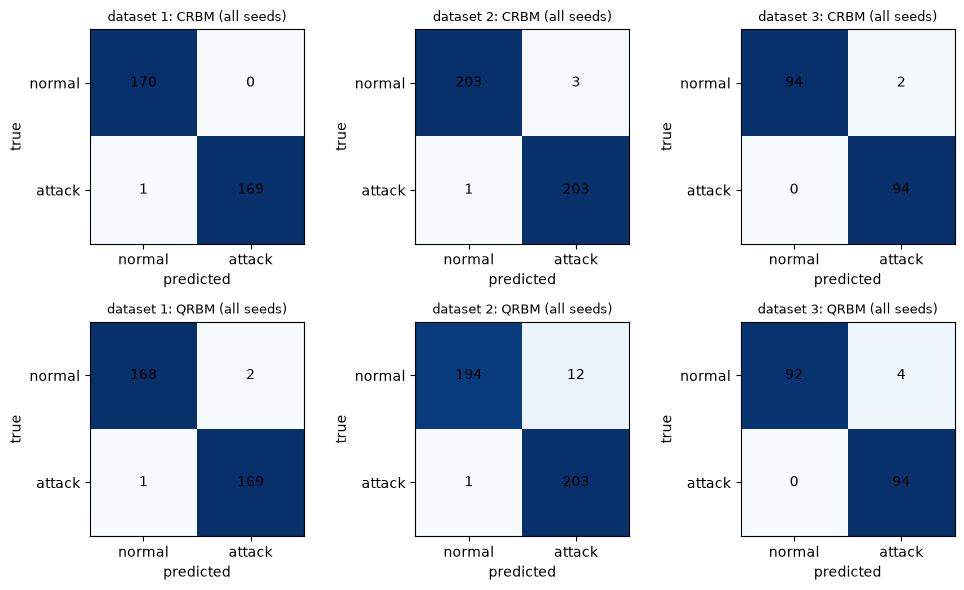

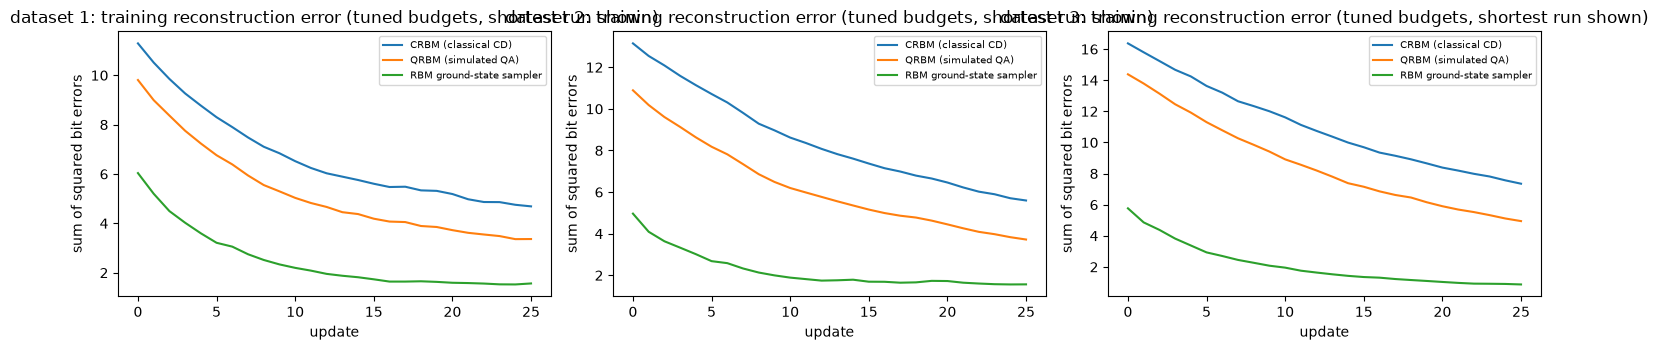

In [20]:
# confusion matrices pooled over seeds (attack = positive), validation-tuned RBMs
fig, ax = plt.subplots(2, 3, figsize=(10, 6))
for j, ds in enumerate(DATASETS):
    for i, (m, ttl) in enumerate([("CRBM (classical CD)", "CRBM"), ("QRBM (simulated QA)", "QRBM")]):
        s = RA[(RA.protocol == "A") & (RA.dataset == ds) & (RA.model == m) & (RA.setting == "tuned on validation")]
        cm = np.array([[s.tn.sum(), s.fp.sum()], [s.fn.sum(), s.tp.sum()]])
        ax[i, j].imshow(cm, cmap="Blues")
        for (r_, c_), v in np.ndenumerate(cm): ax[i, j].text(c_, r_, str(v), ha="center", va="center", color="k")
        ax[i, j].set_xticks([0, 1]); ax[i, j].set_xticklabels(["normal", "attack"]); ax[i, j].set_yticks([0, 1]); ax[i, j].set_yticklabels(["normal", "attack"])
        ax[i, j].set_title(f"{ds}: {ttl} (all seeds)", fontsize=9); ax[i, j].set_xlabel("predicted"); ax[i, j].set_ylabel("true")
plt.tight_layout(); plt.show()

# learning curves: squared reconstruction error of the training image per update (moving average over 25 updates), seed 0 and mean over seeds
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for j, ds in enumerate(DATASETS):
    for k, label in KINDS:
        cs = [np.array(CURVES[(ds, s, k)]) for s in range(N_SEEDS)]
        L = min(len(c) for c in cs); m = np.mean([c[:L] for c in cs], axis=0)
        ax[j].plot(np.convolve(m, np.ones(25) / 25, mode="valid"), label=label)
    ax[j].set_title(f"{ds}: training reconstruction error (tuned budgets, shortest run shown)"); ax[j].set_xlabel("update"); ax[j].set_ylabel("sum of squared bit errors"); ax[j].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 7. Annealing-time sweep

How does the quantum sampler depend on the (unreported) annealing time? A short anneal leaves excitations (noisy sampling, like a high temperature), a long anneal approaches the ground state (the `ground` sampler).
Fixed budget (`SWEEP_UPDATES` updates, `SWEEP_LR`), same binary images as protocol A, all seeds.

acc                           rec                    
dataset   dataset 1 dataset 2 dataset 3 dataset 1 dataset 2 dataset 3
sampler                                                              
classical     100.0     100.0     100.0     100.0     100.0     100.0
ground         92.4      91.5      89.5      99.4      98.0     100.0
qa T=2         90.0      86.6      83.2      84.1      78.6      74.9
qa T=5         99.4      99.8     100.0     100.0     100.0     100.0
qa T=10       100.0      99.8     100.0     100.0     100.0     100.0
qa T=20        98.8      99.3     100.0     100.0     100.0     100.0
qa T=50        97.6      97.6      97.4     100.0      99.0     100.0

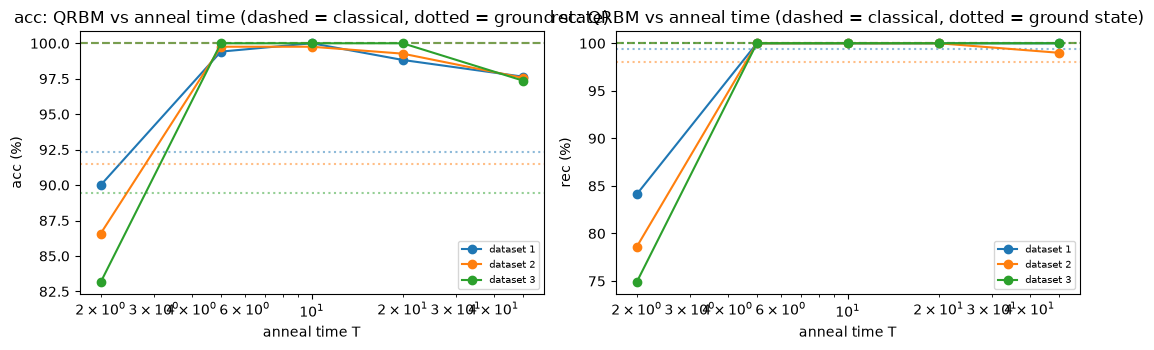

In [21]:
sweep = []
for ds in DATASETS:
    for seed in range(N_SEEDS):
        Btr, ytr, Bte, yte = CACHE[(ds, seed)]; Vtr = embed_label(Btr, ytr)
        for k, T in [("classical", None), ("ground", None)] + [("qa", T) for T in T_SWEEP]:
            prm = train_rbm(Vtr, k, SWEEP_UPDATES, SWEEP_LR, seed, T=T); p = predict_rbm(prm, k, Bte, seed, T=T)
            sweep.append(dict(dataset=ds, seed=seed, sampler=k if k != "qa" else f"qa T={T:g}", **metrics(yte, p)))
SW = pd.DataFrame(sweep)
tab = SW.groupby(["sampler", "dataset"], sort=False)[["acc", "rec"]].mean().round(1).unstack("dataset")
display(tab)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, metric in zip(ax, ["acc", "rec"]):
    for ds in DATASETS:
        a.plot(T_SWEEP, [SW[(SW.dataset == ds) & (SW.sampler == f"qa T={T:g}")][metric].mean() for T in T_SWEEP], "o-", label=ds)
        a.axhline(SW[(SW.dataset == ds) & (SW.sampler == "classical")][metric].mean(), ls="--", color=f"C{list(DATASETS).index(ds)}", alpha=.5)
        a.axhline(SW[(SW.dataset == ds) & (SW.sampler == "ground")][metric].mean(), ls=":", color=f"C{list(DATASETS).index(ds)}", alpha=.5)
    a.set_xscale("log"); a.set_xlabel("anneal time T"); a.set_ylabel(metric + " (%)"); a.legend(fontsize=7)
    a.set_title(f"{metric}: QRBM vs anneal time (dashed = classical, dotted = ground state)")
plt.tight_layout(); plt.show()

## 8. Protocol B: sliding windows and a leakage-free block split

The test sets of protocol A are tiny. Protocol B uses **overlapping windows (stride 1)** to get hundreds of images per class and avoids the leakage that overlapping windows would cause with a random split by cutting each class's message sequence into three **time blocks**:
first 60 % train, next 20 % validation, last 20 % test; windows never cross a block boundary, so no message is shared between train, validation and test. (Test windows overlap each other, so the effective test size is smaller than the window count.)
The extractor is trained on the train block, RBM hyper-parameters are chosen on the validation block, everything is evaluated once on the test block. The paper does not do this; it is a sensitivity check on how much the small random split matters.

In [22]:
from numpy.lib.stride_tricks import sliding_window_view
def block_windows(seq, N, lo, hi):
    part = seq[int(lo * len(seq)): int(hi * len(seq))]
    return sliding_window_view(part, N, axis=0).transpose(0, 2, 1)         # (n_windows, N messages, N signals)

def pipeline_B(ds, seed):
    D = DATASETS[ds]; N = D["N"]; out = {}
    for blk, (lo, hi) in {"tr": (0.0, 0.6), "val": (0.6, 0.8), "te": (0.8, 1.0)}.items():
        wn, wa = block_windows(D["Xn"], N, lo, hi), block_windows(D["Xa"], N, lo, hi)
        out[blk] = (np.concatenate([wn, wa]), np.r_[np.zeros(len(wn), int), np.ones(len(wa), int)])
    (Xtr, ytr), (Xva, yva), (Xte, yte) = out["tr"], out["val"], out["te"]
    t0 = time.time(); ex = FittedExtractor(Xtr, ytr, seed); t_ex = time.time() - t0
    Btr, Ftr = ex.bits(Xtr); Bva, _ = ex.bits(Xva); Bte, Fte = ex.bits(Xte)
    t0 = time.time(); add_row("B", ds, seed, "extractor network (head)", "-", yte, ex.head_predict(Xte), t_ex + time.time() - t0)
    for name, mk in [("RandomForest (48 bits)", lambda: RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1)), ("SVC rbf (48 bits)", lambda: SVC(C=1.0, kernel="rbf", gamma="scale"))]:
        t0 = time.time(); m = mk().fit(flat_bits(Btr), ytr); add_row("B", ds, seed, name, "-", yte, m.predict(flat_bits(Bte)), time.time() - t0)
    for k, label in KINDS:
        upd, lr, _ = tune_rbm(k, Btr, ytr, Bva, yva, seed)
        for setting, (u, l) in [("script (50 upd, lr 0.1)", (SCRIPT_UPDATES, SCRIPT_LR)), ("tuned on validation", (upd, lr))]:
            t0 = time.time(); prm = train_rbm(embed_label(Btr, ytr), k, u, l, seed); p = predict_rbm(prm, k, Bte, seed)
            add_row("B", ds, seed, label, setting, yte, p, time.time() - t0, updates=u, lr=l)
    return len(ytr), len(yva), len(yte)

t_start = time.time()
for ds in DATASETS:
    for seed in range(N_SEEDS_B):
        sizes = pipeline_B(ds, seed)
    print(f"{ds}: windows train/val/test = {sizes}; {N_SEEDS_B} seeds done ({time.time() - t_start:.0f} s cumulative)", flush=True)
RB = pd.DataFrame([r for r in ROWS if r["protocol"] == "B"])
SB = summary(RB, "B")
display(SB[["dataset", "model", "setting", "n_test_per_seed", "acc_mean", "acc_std", "rec_mean", "rec_std", "prec_mean", "f1_mean"]])

dataset 1: windows train/val/test = (1404, 450, 452); 3 seeds done (486 s cumulative)


dataset 2: windows train/val/test = (1564, 506, 506); 3 seeds done (851 s cumulative)


dataset 3: windows train/val/test = (1044, 324, 324); 3 seeds done (1166 s cumulative)


,dataset,model,setting,n_test_per_seed,acc_mean,acc_std,rec_mean,rec_std,prec_mean,f1_mean
0,dataset 1,extractor network (head),-,452,100.0,0.0,100.0,0.0,100.0,100.0
1,dataset 1,RandomForest (48 bits),-,452,100.0,0.0,100.0,0.0,100.0,100.0
2,dataset 1,SVC rbf (48 bits),-,452,100.0,0.0,100.0,0.0,100.0,100.0
3,dataset 1,CRBM (classical CD),"script (50 upd, lr 0.1)",452,99.9,0.1,100.0,0.0,99.7,99.9
4,dataset 1,CRBM (classical CD),tuned on validation,452,99.9,0.1,100.0,0.0,99.7,99.9
5,dataset 1,QRBM (simulated QA),"script (50 upd, lr 0.1)",452,99.9,0.1,100.0,0.0,99.9,99.9
6,dataset 1,QRBM (simulated QA),tuned on validation,452,99.9,0.1,100.0,0.0,99.9,99.9
7,dataset 1,RBM ground-state sampler,"script (50 upd, lr 0.1)",452,98.1,1.6,99.9,0.3,96.5,98.1
8,dataset 1,RBM ground-state sampler,tuned on validation,452,98.1,1.6,100.0,0.0,96.4,98.1
9,dataset 2,extractor network (head),-,506,100.0,0.0,100.0,0.0,100.0,100.0


## 9. Side-by-side comparison with the paper

Verdict rules: a value is **reproduced** when the notebook's mean (protocol A, validation-tuned RBM) is within 2 percentage points of the paper's value,
**not reached** when it is lower by more, **exceeded** when it is higher by more. The qualitative claim "hybrid beats classical" is judged on the per-seed paired differences (reproduced when the mean difference is positive and more than two standard errors; "not distinguishable" otherwise; "reversed" when negative beyond two standard errors).

In [23]:
RA = pd.DataFrame([r for r in ROWS if r["protocol"] == "A"])
def mean_of(ds, model, setting, metric, R=RA):
    return R[(R.dataset == ds) & (R.model == model) & (R.setting == setting)][metric]
def verdict(nb, paper, tol=2.0):
    d = nb - paper
    return "reproduced" if abs(d) <= tol else ("not reached (%.1f pts below)" % -d if d < 0 else "exceeded (%.1f pts above)" % d)

rows = []
for ds in DATASETS:
    for key, model in [("QRBM", "QRBM (simulated QA)"), ("CRBM", "CRBM (classical CD)")]:
        for mi, mname in enumerate(["accuracy", "recall"]):
            met = ["acc", "rec"][mi]
            nb = mean_of(ds, model, "tuned on validation", met).mean(); pv = PAPER[(ds, key)][mi]
            rows.append(dict(claim=f"{key} {mname} ({ds})", paper=pv, notebook=round(nb, 1), verdict=verdict(nb, pv)))
CMP = pd.DataFrame(rows)
display(CMP)

# qualitative claim: hybrid beats classical (paired by seed, validation-tuned RBMs)
def tstat(m, se):
    if m == 0 or not np.isfinite(se): return 0.0
    return float(np.sign(m) * np.inf) if se == 0 else float(m / se)
qual = []
for ds in DATASETS:
    for met, nm in [("acc", "accuracy"), ("rec", "recall")]:
        d = mean_of(ds, "QRBM (simulated QA)", "tuned on validation", met).to_numpy() - mean_of(ds, "CRBM (classical CD)", "tuned on validation", met).to_numpy()
        se = d.std(ddof=1) / np.sqrt(len(d)) if len(d) > 1 else float("nan"); t = tstat(d.mean(), se)
        v = "reproduced" if (d.mean() > 0 and t > 2) else ("reversed" if (d.mean() < 0 and t < -2) else "not distinguishable")
        qual.append(dict(claim=f"QRBM - CRBM {nm} ({ds})", mean_diff_pts=round(d.mean(), 1), std_error=round(se, 1), seeds_qrbm_better=f"{int((d > 0).sum())}/{len(d)}", verdict=v))
        dg = mean_of(ds, "RBM ground-state sampler", "tuned on validation", met).to_numpy() - mean_of(ds, "CRBM (classical CD)", "tuned on validation", met).to_numpy()
        seg = dg.std(ddof=1) / np.sqrt(len(dg)) if len(dg) > 1 else float("nan"); tg = tstat(dg.mean(), seg)
        qual.append(dict(claim=f"(extra) ground state - CRBM {nm} ({ds})", mean_diff_pts=round(dg.mean(), 1), std_error=round(seg, 1), seeds_qrbm_better=f"{int((dg > 0).sum())}/{len(dg)}",
                         verdict="-"))
QL = pd.DataFrame(qual); display(QL)

# Table I
t1 = []
for ds, D in DATASETS.items():
    t1.append(dict(claim=f"Table I {ds}: features / total messages / injected (in log, target ID) ", paper=f"{PAPER_T1[ds]['feat']} / {PAPER_T1[ds]['size']} / {PAPER_T1[ds]['att']}",
                   notebook=f"{len(FEATURES[ds])} / {2*D['n_att']} (by construction) / {int(((CID == D['cid']) & ATT).sum())}",
                   verdict="features reproduced; class sizes only by construction, injected count in the public log NOT reproduced"))
display(pd.DataFrame(t1))

# convergence claim: epochs to the same reconstruction error level (descriptive)
conv_rows = []
for ds in DATASETS:
    fin = {}
    for k, label in KINDS:
        cs = [np.array(CURVES[(ds, s, k)]) for s in range(N_SEEDS)]; L = min(len(c) for c in cs)
        fin[label] = float(np.mean([c[-min(50, L):].mean() for c in cs]))
    conv_rows.append(dict(dataset=ds, **{f"final recon. error {k}": round(v, 2) for k, v in fin.items()}))
display(pd.DataFrame(conv_rows))
print("convergence claim: curves are shown above; both RBMs use the same number of updates here, so 'comparable number of epochs' cannot be tested beyond reading those curves -> cannot be checked quantitatively")
print("\ntotal notebook time: %.1f min" % ((time.time() - T_NOTEBOOK_START) / 60))

,claim,paper,notebook,verdict
0,QRBM accuracy (dataset 1),97.5,99.1,reproduced
1,QRBM recall (dataset 1),94.7,99.4,exceeded (4.7 pts above)
2,CRBM accuracy (dataset 1),86.7,99.7,exceeded (13.0 pts above)
3,CRBM recall (dataset 1),70.7,99.4,exceeded (28.7 pts above)
4,QRBM accuracy (dataset 2),97.0,96.8,reproduced
5,QRBM recall (dataset 2),93.9,99.5,exceeded (5.6 pts above)
6,CRBM accuracy (dataset 2),95.0,99.0,exceeded (4.0 pts above)
7,CRBM recall (dataset 2),89.8,99.5,exceeded (9.7 pts above)
8,QRBM accuracy (dataset 3),98.3,97.9,reproduced
9,QRBM recall (dataset 3),97.2,100.0,exceeded (2.8 pts above)


,claim,mean_diff_pts,std_error,seeds_qrbm_better,verdict
0,QRBM - CRBM accuracy (dataset 1),-0.6,0.4,0/10,not distinguishable
1,(extra) ground state - CRBM accuracy (dataset 1),-5.6,1.6,0/10,-
2,QRBM - CRBM recall (dataset 1),0.0,0.0,0/10,not distinguishable
3,(extra) ground state - CRBM recall (dataset 1),-0.6,0.6,0/10,-
4,QRBM - CRBM accuracy (dataset 2),-2.2,2.3,2/10,not distinguishable
5,(extra) ground state - CRBM accuracy (dataset 2),-5.6,3.1,3/10,-
6,QRBM - CRBM recall (dataset 2),0.0,0.7,1/10,not distinguishable
7,(extra) ground state - CRBM recall (dataset 2),0.5,0.5,1/10,-
8,QRBM - CRBM accuracy (dataset 3),-1.1,1.3,1/10,not distinguishable
9,(extra) ground state - CRBM accuracy (dataset 3),-2.1,1.4,1/10,-


,claim,paper,notebook,verdict
0,Table I dataset 1: features / total messages /...,14 / 2384 / 1192,14 / 2384 (by construction) / 20,features reproduced; class sizes only by const...
1,Table I dataset 2: features / total messages /...,13 / 2648 / 1324,13 / 2648 (by construction) / 23,features reproduced; class sizes only by const...
2,Table I dataset 3: features / total messages /...,19 / 1800 / 900,19 / 1800 (by construction) / 23,features reproduced; class sizes only by const...


,dataset,final recon. error CRBM (classical CD),final recon. error QRBM (simulated QA),final recon. error RBM ground-state sampler
0,dataset 1,6.28,6.11,2.79
1,dataset 2,8.87,7.31,2.63
2,dataset 3,11.86,9.66,3.17


convergence claim: curves are shown above; both RBMs use the same number of updates here, so 'comparable number of epochs' cannot be tested beyond reading those curves -> cannot be checked quantitatively

total notebook time: 34.8 min


### What the numbers say (full run, 10 seeds; markdown written after the run)

* **Quantum RBM accuracy**: 99.1 % / 96.8 % / 97.9 % (datasets 1 / 2 / 3) against the paper's 97.5 % / 97 % / 98.3 %: within the 2-point tolerance for all three. **Recall**: 99.4 % / 99.5 % / 100 % against 94.7 % / 93.9 % / 97.2 %: exceeded.
* **Classical RBM**: 99.7 % / 99.0 % / 98.9 % accuracy and 99.4 % / 99.5 % / 100 % recall, far above the paper's 86.7 % / 95 % / 89.7 % and 70.7 % / 89.8 % / 80.6 %. The poor classical baseline of the paper is **not reproduced**.
* **"The hybrid framework beats the classical-only one" is not reproduced.** The paired difference QRBM minus CRBM in accuracy is -0.6 / -2.2 / -1.1 points (not distinguishable from zero, the QRBM wins in at most 2 of 10 seeds); recall is equal. The exact-ground-state sampler is clearly *worse* than both (about 5 points lower accuracy on datasets 1 and 2).
* **Every simple baseline is perfect.** The extractor network's own head, RandomForest and SVC on the 8 x 6 binary images or on the 64-value code score 100 % accuracy and recall on all three datasets and in both protocols. The fuzzy attack, as decoded here, is trivially separable, and the RBM pipeline can at best match that.
* **Protocol B** (324 to 506 test windows per dataset, leakage-free time blocks) gives the same picture: tuned CRBM and QRBM at 99.9 to 100 % on datasets 1 and 2; the ground-state sampler is lower (85 % on dataset 2).
* **Annealing time**: a very short anneal (T = 2) leaves many excitations and hurts accuracy (about 83 to 90 %); T = 5 to 20 behaves like the classical sampler (99 to 100 %); a long anneal (T = 50) drifts towards the ground-state sampler's behaviour.
* **Table I**: the feature counts 14 / 13 / 19 are reproduced by the DBC decoding; the class sizes hold only by construction (the public log has 20 / 23 / 23 injected frames with the target IDs).
* The paper's convergence statement cannot be checked quantitatively (the notebook trains both RBMs for the same number of updates); the training curves show similar reconstruction errors for CRBM and QRBM.

Caveats: the three datasets are not the paper's (attack class pooled over IDs, see the table at the top), the test sets of protocol A are 19 to 41 images, and the quantum sampler is a simulated closed-system anneal with an assumed anneal time and coefficient scaling, not D-Wave hardware.


## 10. Reading the paper critically

* **What the quantum computer actually does here.** The public QRBM code samples *one layer given the other* by building a QUBO over that layer's units and taking the best sample (`sampleset.first`, one read). Such a QUBO has no quadratic terms (see section 5), its ground state is the threshold rule, and the check above shows that simulated annealing and exact enumeration return exactly that. The annealer can only add noise to a rule that two lines of NumPy implement. The comparison "quantum RBM vs classical RBM" is therefore a comparison between *near-deterministic* sampling and *stochastic* CD sampling, and the `ground` sampler isolates that effect. Whether any benefit comes from quantum effects at all is not what the experiment tests.
* **Training length.** In the public scripts one "epoch" is **one training image** (50 epochs = 50 updates on 50 images). With so little training the learned weights are close to their random initialisation; what a model then does depends strongly on how its samples are drawn. The tuned settings here train much longer.
* **The paper's class sizes cannot come from the cited public log.** After filtering on the CAN ID the public Survival-Analysis fuzzy log holds about 20 injected frames per ID, not 900 to 1324; the authors must have used a different file. The notebook therefore builds the attack class from real injected frames of any ID (their payloads are random and ID-independent, tested above). The attack class is the *same* kind of random-byte frame in every dataset, only decoded with a different layout; this makes the problem easier than a targeted attack on one signal would be.
* **Tiny test sets and tuning on the test set.** 19 to 41 test images (one image = 2.4 to 5.3 accuracy points) and "hyper-parameters optimised to yield the best performance" without a validation split mean the paper's single numbers carry a large optimism and sampling error. Here a validation split chooses the settings and ten random splits give a spread.
* **Possible leakage in the public scripts.** In `CNN_feature_extraction.ipynb` (cell 3) the test attack images are taken from the *normal* data frame, the test labels use the training label frame, and the scalers are re-fitted on the test data. We could not check what version produced the paper's numbers and did not replicate any of this.
* **Easy attack.** The fuzzy attack injects random bytes; a simple rule (signal ranges, checksum validity) separates it, and the RandomForest / SVC / the extractor network itself on the same binary images are strong baselines. An RBM that reconstructs label pixels is a roundabout classifier; the useful comparison is with those baselines, which the paper does not report.
* **No hardware.** Real D-Wave noise, embedding and chain breaks are not simulated; the closed-system anneal is the idealised limit.

## 11. Exercises

1. Set `ANNEAL_T` to 2 and to 50 and re-run sections 5 to 7. How do the QRBM's accuracy and recall move relative to the classical RBM and to the `ground` sampler?
2. Replace the conditional-layer QUBO by the *joint* QUBO over `(v, h)` with the 4096 coupling terms and draw the negative phase of CD with `dwave-samplers` (simulated annealing at `beta = 1`). Does the quantum-style sampler help now that the problem is no longer separable?
3. Change `H_RANGE` from 4 to 1 and to 20 (less / more aggressive rescaling). Explain the effect with the response curves of section "Quantum Circuit Architecture".
4. Implement the paper's 8 x 8 -> 8 x 6 resize as a crop (drop two columns) instead of average pooling and compare the baselines.
5. Build a harder attack class by taking only the **20 genuinely injected frames of the target ID** plus time-shifted copies of regular frames; discuss what a labelled dataset of such a targeted attack would need.